# Tecnología Digital VI - Trabajo Práctico 1 (2026 - 2do semestre)
#### Integrantes: Candela Guinzburg, Victoria Iasillo y María Bullrich

**Instrucciones de ejecución:** colocar `telco.csv` en la misma carpeta que este notebook y ejecutar las celdas en orden. Se utilizan `pandas`, `numpy`, `matplotlib`, `seaborn` y `scikit-learn`.


**Aclaración sobre reproducibilidad:** la selección de variables utiliza `StratifiedKFold` con `shuffle=True` y `random_state=42`. La semilla fija cómo se distribuyen las observaciones entre los folds, permitiendo repetir la misma división en un mismo entorno. Sin una semilla, los folds podrían cambiar en cada ejecución y, como consecuencia, también podrían variar las métricas y las variables seleccionadas. Aun con la semilla establecida, pueden aparecer pequeñas diferencias entre computadoras debido a las versiones de Python, `scikit-learn`, `pandas` o `numpy` y a la resolución de empates numéricos. De todos modos, las alternativas mejor posicionadas se mantienen aproximadamente estables, principalmente **Opción 1 - Forward** y **Opción 2 - Forward**. En este trabajo, la elección automática de la mayor Balanced Accuracy en Validation se utiliza como una referencia comparativa para continuar el análisis, y no como una afirmación de que esa alternativa sea universal o definitivamente superior en cualquier partición o entorno.

### Descripción del archivo utilizado

El dataset se encuentra en el archivo `telco.csv`. Cada fila representa un cliente y las columnas contienen información demográfica, los servicios contratados, datos de facturación y la variable objetivo `Churn`.

Lo cargamos con `pd.read_csv()` y luego revisamos sus tipos de datos para detectar columnas que necesiten limpieza antes de entrenar el modelo.


In [1]:
#Importamos las librerías necesarias para el análisis de datos y la construcción del modelo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, confusion_matrix
from sklearn.utils import resample

# Cargamos el dataset
df = pd.read_csv("telco.csv")

# Mostramos las primeras filas del dataset para tener una idea de su estructura y contenido
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

### Descripción del conjunto de datos y problema de negocio

El dataset de Telco Customer Churn tiene información de 7.043 clientes de una empresa de telecomunicaciones, con 21 variables en total. Se pueden agrupar en cuatro bloques:

- **Demográficas:** `gender`, `SeniorCitizen`, `Partner`, `Dependents`.
- **Servicios contratados:** `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`.
- **Información de la cuenta:** `tenure` , `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`.
- **Variable objetivo:** `Churn` (Yes/No), que indica si el cliente abandonó la empresa durante el último mes.

El **problema de negocio** consiste en identificar con anticipación qué clientes tienen mayor probabilidad de abandonar el servicio, para que la empresa pueda actuar antes de perderlos, por ejemplo ofreciéndoles algún beneficio de retención. Nuestro trabajo es usar las características de cada cliente para encontrar los patrones asociados a ese abandono.

Antes de construir el modelo, hicimos un análisis exploratorio para entender mejor los datos y detectar qué variables valía la pena mirar con más atención. Empezamos por lo más directo: cómo se reparte la variable objetivo.

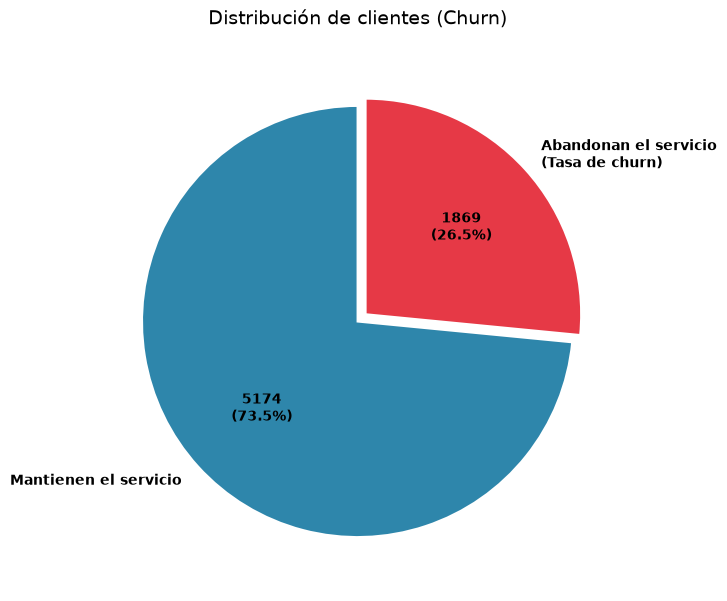

In [2]:


churn_counts = df["Churn"].value_counts()
total = churn_counts.sum()
colors = ["#2E86AB", "#E63946"]

labels_map = {
    "Yes": "Abandonan el servicio\n(Tasa de churn)",
    "No": "Mantienen el servicio"
}
custom_labels = [labels_map.get(str(label), label) for label in churn_counts.index]


def formato_valores(pct):
    val = int(round(pct * total / 100.0))
    return f"{val}\n({pct:.1f}%)"


plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts.values,
    labels=custom_labels,
    autopct=formato_valores,
    colors=colors,
    startangle=90,
    explode=(0, 0.05),
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    textprops={"fontweight": "bold"}
)

plt.title("Distribución de clientes (Churn)", fontsize=14, pad=20)
plt.show()

El gráfico confirma que el dataset está desbalanceado: el **73,5 %** de los clientes mantiene el servicio y solo el **26,5 %** presenta Churn. Esta diferencia es importante para lo que sigue, porque con esta proporción mirar solo Accuracy puede resultar engañoso, ya que puede verse alto aunque el modelo tenga un mal desempeño sobre la clase minoritaria. Por este motivo, más adelante utilizamos Balanced Accuracy como métrica principal, ya que considera el desempeño sobre ambas clases.

A continuación agrupamos `tenure` en intervalos para observar mejor cómo cambia el Churn según la antigüedad del cliente. Esta agrupación se usa solamente para el gráfico; para el modelo seguimos usando `tenure` como variable numérica, no agrupada.

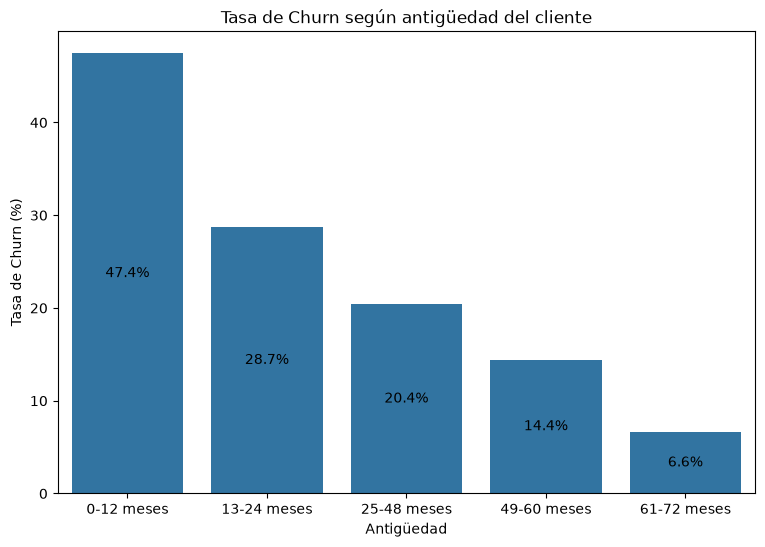

In [3]:
# Tasa de Churn según antigüedad del cliente

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 60, 72],
    labels=["0-12 meses", "13-24 meses", "25-48 meses", "49-60 meses", "61-72 meses"],
    include_lowest=True
)

churn_tenure = (
    df.assign(
        ChurnBinary=(df["Churn"] == "Yes").astype(int)
    )
    .groupby("TenureGroup", observed=False)["ChurnBinary"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=churn_tenure,
    x="TenureGroup",
    y="ChurnBinary"
)

plt.title("Tasa de Churn según antigüedad del cliente")
plt.xlabel("Antigüedad")
plt.ylabel("Tasa de Churn (%)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center"
    )

plt.show()

La relación es clara: los clientes con menos de un año de antigüedad (0 a 12 meses) tienen una tasa de Churn de **47,4 %**, mientras que los que llevan entre 61 y 72 meses bajan a **6,6 %**. Esto sugiere que los primeros meses son un período crítico para las acciones de retención.

Repetimos el mismo análisis agrupando `MonthlyCharges`, para estudiar si el cargo mensual también se relaciona con el abandono.

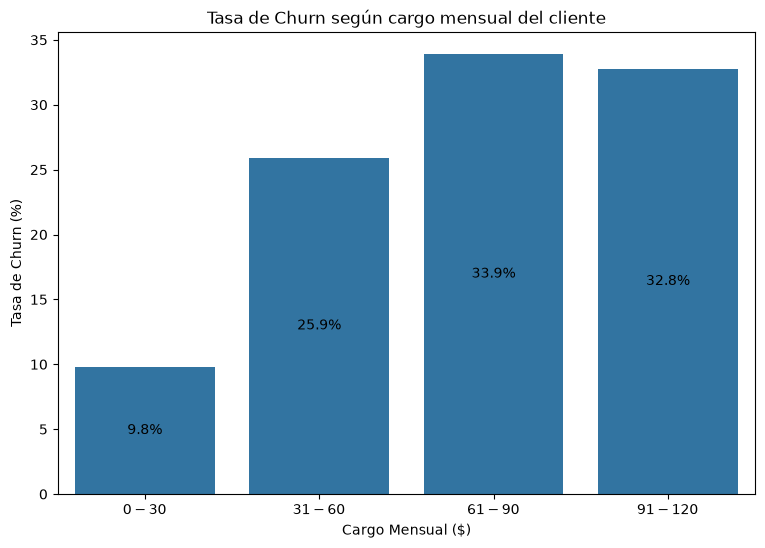

In [4]:

df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 30, 60, 90, 120],
    labels=["$0 - $30", "$31 - $60", "$61 - $90", "$91 - $120"],
    include_lowest=True
)

churn_charges = (
    df.assign(
        ChurnBinary=(df["Churn"] == "Yes").astype(int)
    )
    .groupby("MonthlyChargesGroup", observed=False)["ChurnBinary"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=churn_charges,
    x="MonthlyChargesGroup",
    y="ChurnBinary"
)

plt.title("Tasa de Churn según cargo mensual del cliente")
plt.xlabel("Cargo Mensual ($)")
plt.ylabel("Tasa de Churn (%)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center"
    )

plt.show()

Los clientes que pagan hasta 30 dólares tienen la menor tasa de Churn (**9,8 %**). La tasa aumenta en los grupos siguientes hasta llegar a **33,9 %** entre 61 y 90 dólares, y baja levemente a **32,8 %** en el grupo de mayor cargo. La relación existe, entonces, pero no es estrictamente creciente.

Para entender mejor este resultado, armamos un tercer gráfico que combina cantidad de servicios contratados, cargo mensual promedio y tasa de Churn, ya que un cargo alto no significa lo mismo si corresponde a un solo servicio caro que si corresponde a un paquete más amplio.

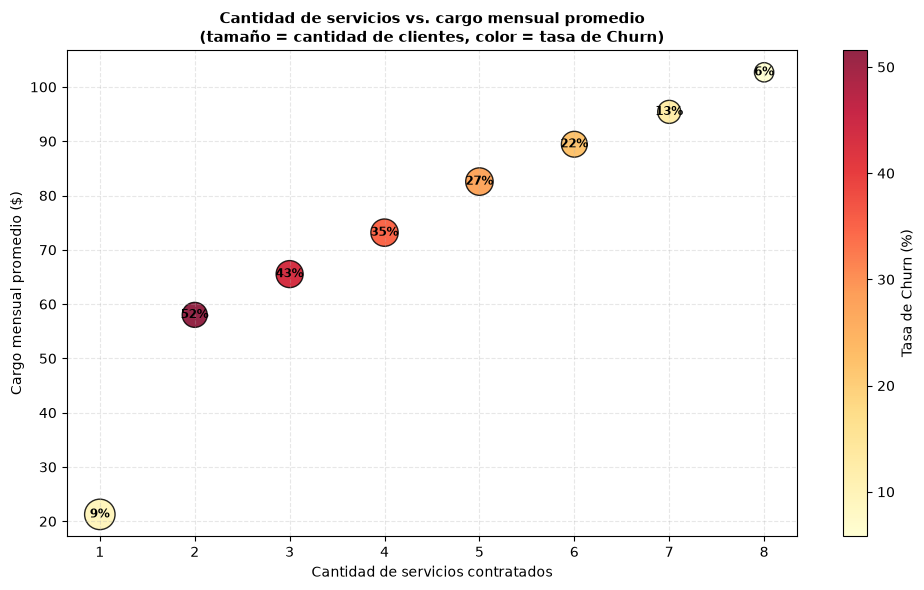

In [5]:

# Gráfico 6: Cantidad de servicios contratados vs. cargo mensual y Churn
df_grafico = df.copy()
df_grafico["ServiceCount"] = 0
df_grafico["ServiceCount"] += (df_grafico["PhoneService"] == "Yes").astype(int)
df_grafico["ServiceCount"] += (df_grafico["InternetService"] != "No").astype(int)

other_services = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]
for col in other_services:
    df_grafico["ServiceCount"] += (df_grafico[col] == "Yes").astype(int)

summary = df_grafico.groupby("ServiceCount").agg(
    MonthlyCharges=("MonthlyCharges", "mean"),
    ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100),
    Customers=("customerID", "count")
).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))

# Usamos np.sqrt para que los valores de miles de clientes no exploten la escala
sizes = np.sqrt(summary["Customers"]) * 12

scatter = ax.scatter(
    summary["ServiceCount"], summary["MonthlyCharges"],
    s=sizes, c=summary["ChurnRate"], cmap="YlOrRd",
    alpha=0.85, edgecolors="black", linewidth=1.0
)

for _, row in summary.iterrows():
    ax.annotate(f"{row['ChurnRate']:.0f}%", (row["ServiceCount"], row["MonthlyCharges"]),
                ha="center", va="center", fontsize=8.5, fontweight="bold", color="black")

plt.colorbar(scatter, label="Tasa de Churn (%)")
ax.set_title("Cantidad de servicios vs. cargo mensual promedio\n(tamaño = cantidad de clientes, color = tasa de Churn)", fontsize=11, fontweight="bold")
ax.set_xlabel("Cantidad de servicios contratados")
ax.set_ylabel("Cargo mensual promedio ($)")
ax.set_xticks(summary["ServiceCount"])
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

En el gráfico de burbujas se observa que el cargo mensual promedio aumenta a medida que el cliente contrata más servicios. Lo interesante es que el Churn no baja de manera lineal: los clientes con un solo servicio ya tienen una tasa baja, pero entre quienes tienen dos o más servicios la tasa cae de forma notable a medida que el paquete se amplía, pasando de **51,6 %** con dos servicios a **5,8 %** con ocho. El tamaño de las burbujas también recuerda que no todos los grupos tienen la misma cantidad de clientes.

Con esto ya tenemos una idea de las variables numéricas. A continuación armamos un panel para comparar cómo se comporta el Churn según las variables categóricas más relevantes para el negocio.


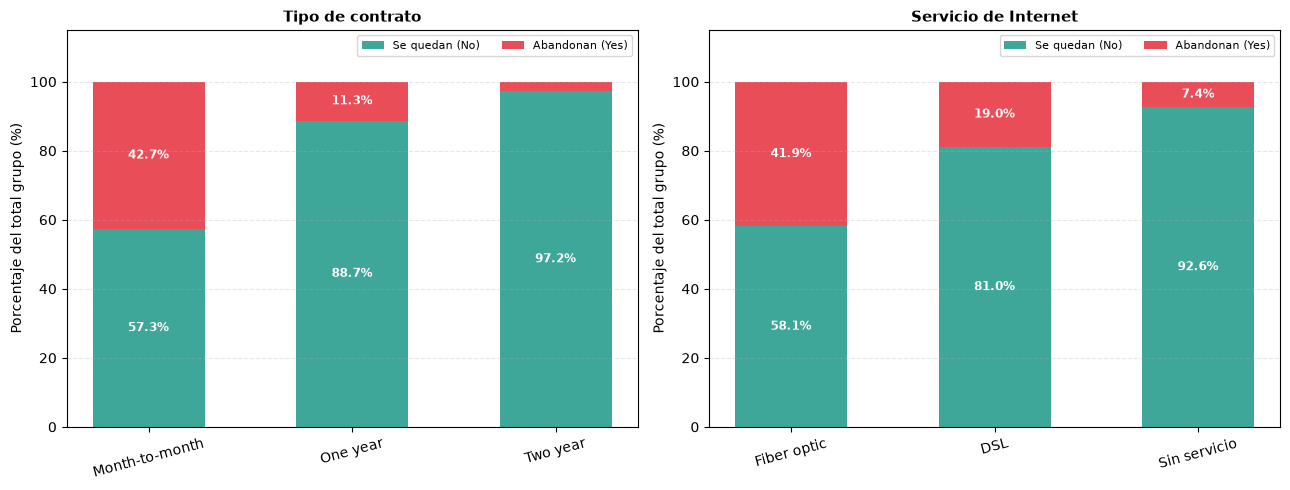

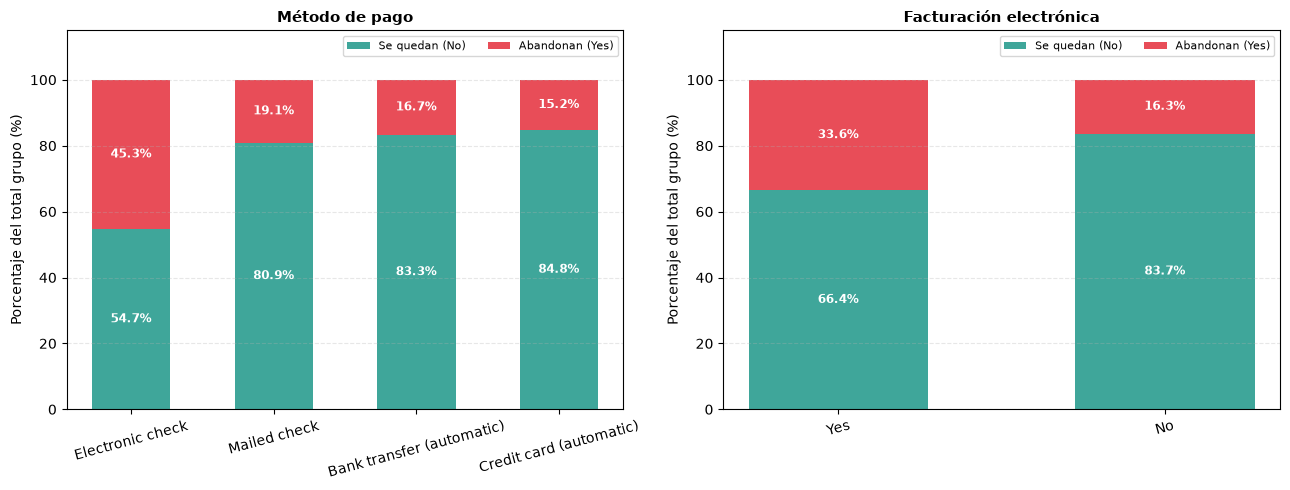

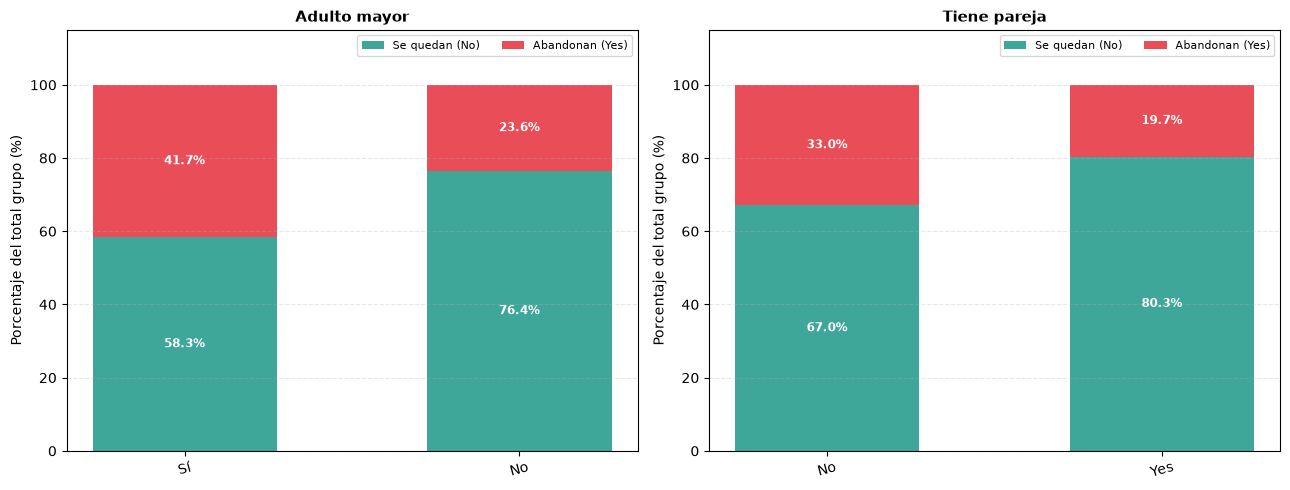

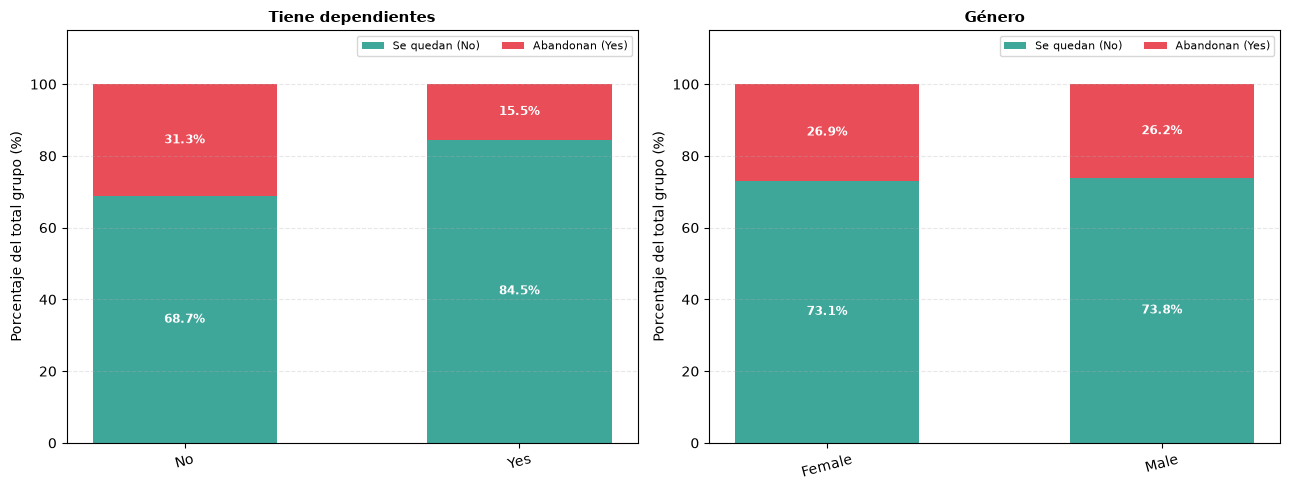

In [6]:


cat_vars = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
            "SeniorCitizen", "Partner", "Dependents", "gender"]
cat_titles = ["Tipo de contrato", "Servicio de Internet", "Método de pago", "Facturación electrónica",
              "Adulto mayor", "Tiene pareja", "Tiene dependientes", "Género"]

# Colores para la pila: Verde/Azul abajo (Retención), Rojo arriba (Abandono)
colors_stack = {"No": "#2A9D8F", "Yes": "#E63946"}

# Generar gráficos de a pares (1 fila x 2 columnas)
for i in range(0, len(cat_vars), 2):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    
    pair_vars = cat_vars[i:i+2]
    pair_titles = cat_titles[i:i+2]
    
    for ax, col, title in zip(axes, pair_vars, pair_titles):
        tmp = df.copy()
        
        # Limpieza y mapeo de nombres
        if col == "InternetService":
            tmp[col] = tmp[col].replace({"No": "Sin servicio"})
        tmp[col] = tmp[col].map({1: "Sí", 0: "No", "1": "Sí", "0": "No"}).fillna(tmp[col])
        
        # 1. Calcular proporciones en % por categoría
        cross_tab = pd.crosstab(tmp[col], tmp["Churn"], normalize="index") * 100
        
        # Ordenar categorías según mayor porcentaje de Churn (Yes)
        cross_tab = cross_tab.sort_values(by="Yes", ascending=False)
        
        # 2. Dibujar barras apiladas
        bars_no = ax.bar(cross_tab.index.astype(str), cross_tab["No"], 
                         label="Se quedan (No)", color=colors_stack["No"], alpha=0.9, width=0.55)
        bars_yes = ax.bar(cross_tab.index.astype(str), cross_tab["Yes"], 
                          bottom=cross_tab["No"], label="Abandonan (Yes)", color=colors_stack["Yes"], alpha=0.9, width=0.55)
        
        # Configuración visual
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.set_ylabel("Porcentaje del total grupo (%)")
        ax.set_ylim(0, 115) # Margen superior para la leyenda
        ax.tick_params(axis="x", rotation=15)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        
        # 3. Añadir etiquetas adentro de cada sección de la barra
        for i_cat in range(len(cross_tab)):
            val_no = cross_tab["No"].iloc[i_cat]
            val_yes = cross_tab["Yes"].iloc[i_cat]
            
            # Etiqueta abajo (No Churn)
            if val_no > 5: # Solo muestra texto si el segmento es visible
                ax.text(i_cat, val_no / 2, f"{val_no:.1f}%", 
                        ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
            
            # Etiqueta arriba (Yes Churn)
            if val_yes > 5:
                ax.text(i_cat, val_no + (val_yes / 2), f"{val_yes:.1f}%", 
                        ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)

        ax.legend(fontsize=8, loc="upper right", ncol=2)

    plt.tight_layout()
    plt.show()

Las diferencias más grandes aparecen en `Contract`, `InternetService` y `PaymentMethod`. Los contratos mes a mes tienen **42,7 %** de Churn frente a **2,8 %** en contratos de dos años, una diferencia considerable. Fibra óptica alcanza **41,9 %** y Electronic check **45,3 %**. También se observan tasas más altas entre adultos mayores, clientes sin pareja, sin dependientes y con facturación electrónica. Por género, en cambio, las tasas son muy parecidas.

Estas comparaciones muestran asociaciones, no relaciones de causa. Para profundizar en algunas combinaciones que parecían relevantes, más adelante reservamos Train, Validation y Test y armamos dos mapas de calor utilizando únicamente Train.

### Datos numéricos no reconocidos como numéricos


In [7]:
# Revisamos los tipos de datos
print(df.dtypes)
print("---")
print(df[["MonthlyCharges", "TotalCharges"]].dtypes)

customerID                  str
gender                      str
SeniorCitizen             int64
Partner                     str
Dependents                  str
tenure                    int64
PhoneService                str
MultipleLines               str
InternetService             str
OnlineSecurity              str
OnlineBackup                str
DeviceProtection            str
TechSupport                 str
StreamingTV                 str
StreamingMovies             str
Contract                    str
PaperlessBilling            str
PaymentMethod               str
MonthlyCharges          float64
TotalCharges                str
Churn                       str
TenureGroup            category
MonthlyChargesGroup    category
dtype: object
---
MonthlyCharges    float64
TotalCharges          str
dtype: object


Al revisar los tipos de datos detectamos que `TotalCharges` estaba almacenada como texto, a pesar de representar un monto en dólares.

Esto ocurre porque hay 11 filas con un espacio en blanco en lugar de un número. Al convertir la columna con `pd.to_numeric(..., errors="coerce")`, esos espacios pasan a ser `NaN`, que sí podemos detectar y tratar de manera explícita (más adelante comprobamos que esos 11 casos corresponden justamente a clientes con `tenure = 0`, y los completamos con 0). `TenureGroup` aparece como categórica simplemente porque la creamos nosotras para el análisis exploratorio, no porque venga así en el dataset original.

Si esta anomalía no se detectara, `TotalCharges` seguiría tratándose como texto y no podría usarse en operaciones numéricas ni en el modelo. En el mejor de los casos esto rompería el código, y en el peor, la variable quedaría afuera del análisis sin que se note.

In [8]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df[["MonthlyCharges", "TotalCharges"]].dtypes)


MonthlyCharges    float64
TotalCharges      float64
dtype: object


### Estadísticas descriptivas

Además de los gráficos, revisamos las estadísticas descriptivas: para las variables numéricas nos interesa la escala, el centro y la dispersión, y para las categóricas resumimos cantidad de valores, categorías distintas, la más frecuente y su frecuencia.

In [9]:
numeric_summary = df.assign(ServiceCount=df_grafico["ServiceCount"])[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ServiceCount"
]].describe().T

categorical_columns_summary = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "Churn",
    "TenureGroup"
]
categorical_summary = df[
    categorical_columns_summary
].describe().T

print("Resumen de variables numéricas:")
display(numeric_summary)

print("Resumen de variables categóricas:")
display(categorical_summary)

Resumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80
ServiceCount,7043.0,3.724407,2.100232,1.00,2.00,4.000,5.0000,8.00


Resumen de variables categóricas:


,count,unique,top,freq
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095
TechSupport,7043,3,No,3473


El resumen muestra que las variables numéricas trabajan con escalas muy distintas entre sí: `tenure` tiene una media de 32,37 meses, `MonthlyCharges` de 64,76 y `TotalCharges` de 2283,30. Esta diferencia de magnitudes confirma la necesidad de escalar antes de aplicar KNN.

También notamos que `TotalCharges` tiene 7032 observaciones en lugar de 7043; ahí están los 11 valores faltantes que mencionamos antes, y que resolvemos en la sección siguiente.

Entre las categóricas, `Month-to-month` es el contrato más frecuente y 5174 de los 7043 clientes son `No Churn`. Este último dato ya anticipaba el desbalance que vimos en el primer gráfico, y explica por qué más adelante no evaluamos el modelo únicamente con Accuracy.

## 2. Preprocesamiento y prevención de Data Leakage

In [10]:

# Valores que vamos a considerar como faltantes
valores_faltantes = ["NA", "N/A", "Unknown","unknown","UNKNOWN", "?", "na", "n/a", "n/", "none", "None", "NONE", "null", "NULL", "Null"]

# Recorremos las columnas y reemplazamos las distintas formas de representar faltantes
for col in df.columns:
    df[col] = df[col].apply(
        lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x
    )

    df[col] = df[col].replace(valores_faltantes, np.nan)

In [11]:
# Cantidad de valores faltantes por columna
faltantes = df.isna().sum()
print(faltantes[faltantes > 0])

# Miramos las filas donde TotalCharges es NaN
filas_totalcharges_nan = df[df["TotalCharges"].isna()]
print(filas_totalcharges_nan[[
    "customerID", "tenure", "MonthlyCharges", "TotalCharges"
]])

# Contamos ceros y NaN por separado porque no significan lo mismo
print("Ceros en tenure:", (df["tenure"] == 0).sum())
print("NaN en tenure:", df["tenure"].isna().sum())

print("Ceros en MonthlyCharges:", (df["MonthlyCharges"] == 0).sum())
print("NaN en MonthlyCharges:", df["MonthlyCharges"].isna().sum())

print("Ceros en TotalCharges:", (df["TotalCharges"] == 0).sum())
print("NaN en TotalCharges:", df["TotalCharges"].isna().sum())

TotalCharges    11
dtype: int64
      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN
Ceros en tenure: 11
NaN en tenure: 0
Ceros en MonthlyCharges: 0
NaN en MonthlyCharges: 0
Ceros en TotalCharges: 0
NaN en TotalCharges: 11


In [12]:
# Comprobamos que los TotalCharges faltantes corresponden a tenure = 0
print(filas_totalcharges_nan["tenure"].value_counts())

# Como son clientes nuevos, todavía no acumularon cargos totales
# Reemplazamos solamente esos NaN por el valor fijo 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

tenure
0    11
Name: count, dtype: int64


In [13]:
# Volvemos a revisar los valores faltantes
print(df.isna().sum()[df.isna().sum() > 0])

print("Clientes con tenure = 0:", (df["tenure"] == 0).sum())
print("TotalCharges iguales a 0:", (df["TotalCharges"] == 0).sum())

Series([], dtype: int64)
Clientes con tenure = 0: 11
TotalCharges iguales a 0: 11


### Separación Train / Validation / Test

Antes de analizar las combinaciones de Churn que originan las nuevas variables, reservamos 60 % de los clientes para Train, 20 % para Validation y 20 % para Test, utilizando `stratify` para conservar aproximadamente la proporción de Churn en los tres conjuntos.

En este punto separamos únicamente los índices. Las transformaciones fijas posteriores se calculan fila por fila y no aprenden parámetros. Train se utiliza para aprender el preprocessing y seleccionar variables; Validation, para comparar alternativas; y Test queda reservado para la evaluación final.

In [14]:
y = df["Churn"].map({"No": 0, "Yes": 1}).astype("int64")

indices_train, indices_temp = train_test_split(
    df.index, test_size=0.40, random_state=42, stratify=y
)
indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    random_state=42,
    stratify=y.loc[indices_temp]
)

print("Train reservado:", len(indices_train))
print("Validation reservado:", len(indices_val))
print("Test reservado:", len(indices_test))

Train reservado: 4225
Validation reservado: 1409
Test reservado: 1409


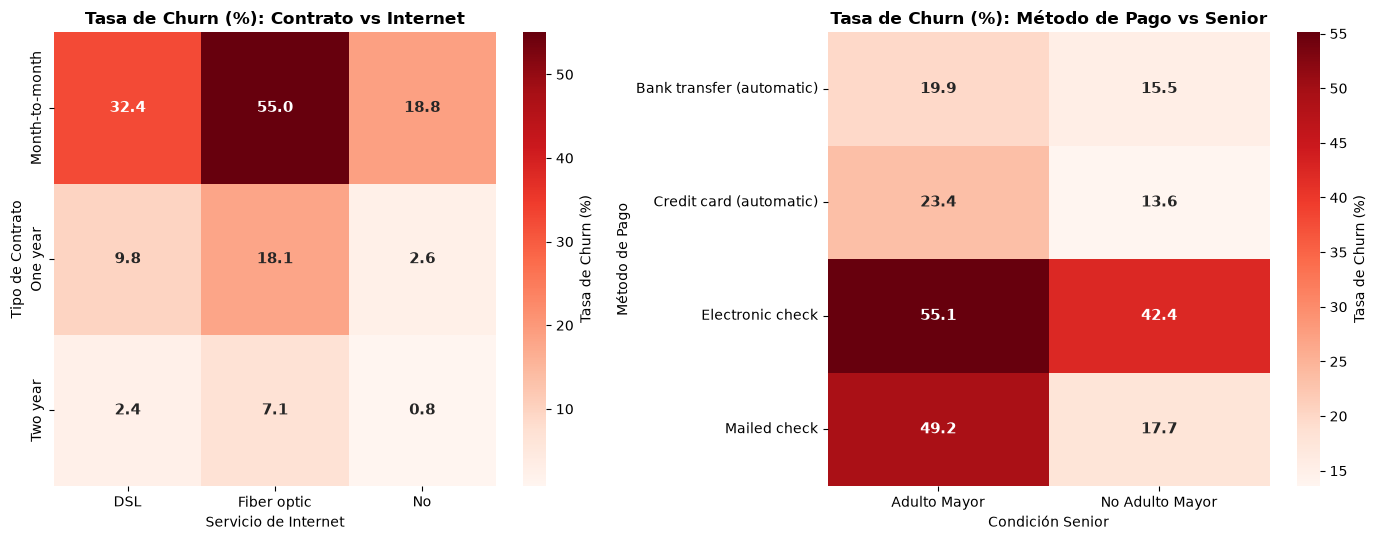

In [15]:


# Preparación de datos
df_temp = df.loc[indices_train].copy()
df_temp["SeniorCitizen"] = df_temp["SeniorCitizen"].map({1: "Adulto Mayor", 0: "No Adulto Mayor", "1": "Adulto Mayor", "0": "No Adulto Mayor"}).fillna(df_temp["SeniorCitizen"])
df_temp["ChurnBinary"] = (df_temp["Churn"] == "Yes").astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Heatmap 1: Contrato vs Servicio de Internet
pivot1 = df_temp.pivot_table(index="Contract", columns="InternetService", values="ChurnBinary", aggfunc="mean") * 100
sns.heatmap(pivot1, annot=True, fmt=".1f", cmap="Reds", cbar_kws={'label': 'Tasa de Churn (%)'}, ax=axes[0], annot_kws={"size": 11, "weight": "bold"})
axes[0].set_title("Tasa de Churn (%): Contrato vs Internet", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Servicio de Internet")
axes[0].set_ylabel("Tipo de Contrato")

# Heatmap 2: Método de Pago vs Adulto Mayor
pivot2 = df_temp.pivot_table(index="PaymentMethod", columns="SeniorCitizen", values="ChurnBinary", aggfunc="mean") * 100
sns.heatmap(pivot2, annot=True, fmt=".1f", cmap="Reds", cbar_kws={'label': 'Tasa de Churn (%)'}, ax=axes[1], annot_kws={"size": 11, "weight": "bold"})
axes[1].set_title("Tasa de Churn (%): Método de Pago vs Senior", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Condición Senior")
axes[1].set_ylabel("Método de Pago")

plt.tight_layout()
plt.show()

En el primer mapa, calculado únicamente con Train, la combinación con mayor tasa de Churn es **fibra óptica y contrato mes a mes (55,0 %)**. Esa tasa baja considerablemente al extender el contrato: 18,1 % con un año y 7,1 % con dos años dentro de fibra óptica. Esto nos llevó a crear `FibraOptica_Contrato_mensual`, una variable que identifica específicamente ese segmento.

En el segundo mapa, Electronic check presenta tasas altas tanto en adultos mayores como en no mayores, con **55,1 %** y **42,4 %** respectivamente, y entre los adultos mayores también se destaca Mailed check, con **49,2 %**. Los métodos de pago automáticos tienen tasas bastante menores. Con esto armamos otra variable, `Adulto_mayor_Pago_Mensual`, para identificar a los adultos mayores que pagan de forma no automática.

Estas dos variables nuevas resumen combinaciones observadas en el análisis exploratorio de Train, pero no las tratamos como una mejora asegurada: más adelante las comparamos formalmente contra no usarlas, en Validation.

### Transformaciones fijas y creación de nuevas variables

Luego de reservar los conjuntos, hicimos las transformaciones que dependen solamente del significado de cada dato, sin necesidad de aprender nada del conjunto. Las respuestas `Yes`/`No` pasan a 1/0, y en los servicios adicionales `No internet service` también pasa a 0, ya que en la práctica indica que el cliente no tiene ese servicio contratado. La información de si el cliente tiene o no Internet se conserva en `InternetService`.

Después creamos cuatro variables nuevas. La asignación de los clientes a Train, Validation y Test ya había sido reservada, y las dos variables basadas en combinaciones de Churn se definieron observando únicamente Train:

- `PhoneServiceCount`: 0 si no tiene teléfono, 1 si tiene una línea, 2 si tiene varias.
- `InternetServiceCount`: cuántos de los seis servicios adicionales de Internet tiene contratados (entre 0 y 6).
- `FibraOptica_Contrato_mensual`: 1 si tiene fibra óptica y contrato mes a mes.
- `Adulto_mayor_Pago_Mensual`: 1 si es adulto mayor y paga con un medio no automático (`Electronic check` o `Mailed check`).

Las dos primeras son resúmenes de servicios relacionados. Las otras dos surgen directamente de las combinaciones que mostraron tasas de Churn más altas en los mapas de calor. Ninguna reemplaza a sus variables originales: en las Opciones 2 y 4 las agregamos para comprobar si realmente aportan información útil, sin darlo por sentado.

Todas se calculan fila por fila, usando solo información del propio cliente. Al momento de crearlas, la asignación de cada cliente a Train, Validation y Test ya estaba fijada, y las combinaciones relacionadas con Churn se eligieron únicamente con el análisis de Train. Por eso Validation y Test no intervienen en su definición ni en ningún parámetro aprendido.

In [16]:
# Columnas que originalmente tienen respuestas Yes / No.
yes_no_columns = [
    "Partner", "Dependents", "PhoneService", "PaperlessBilling",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies"
]

for col in yes_no_columns:
    df[col] = df[col].map({
        "Yes": 1,
        "No": 0,
        "No internet service": 0
    }).astype("int64")

df["SeniorCitizen"] = df["SeniorCitizen"].astype("int64")
df["gender"] = df["gender"].map({"Female": 1, "Male": 0}).astype("int64")

# MultipleLines vale 1 solo si el cliente tiene múltiples líneas.
df["MultipleLines"] = df["MultipleLines"].map({
    "Yes": 1,
    "No": 0,
    "No phone service": 0
}).astype("int64")

binary_columns = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "PaperlessBilling", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
]

categorical_columns = ["InternetService", "Contract", "PaymentMethod"]

internet_addons = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies"
]

# Las cuatro variables nuevas se calculan después de reservar los índices.
df["PhoneServiceCount"] = df["PhoneService"] + df["MultipleLines"]
df["InternetServiceCount"] = df[internet_addons].sum(axis=1)
df["FibraOptica_Contrato_mensual"] = (
    (df["InternetService"] == "Fiber optic") &
    (df["Contract"] == "Month-to-month")
).astype("int64")
df["Adulto_mayor_Pago_Mensual"] = (
    (df["SeniorCitizen"] == 1) &
    (df["PaymentMethod"].isin(["Electronic check", "Mailed check"]))
).astype("int64")

for col in binary_columns + [
    "FibraOptica_Contrato_mensual", "Adulto_mayor_Pago_Mensual"
]:
    print(col, sorted(df[col].unique()))

print("Rango de PhoneServiceCount:", df["PhoneServiceCount"].min(), "a", df["PhoneServiceCount"].max())
print("Rango de InternetServiceCount:", df["InternetServiceCount"].min(), "a", df["InternetServiceCount"].max())


gender [np.int64(0), np.int64(1)]
SeniorCitizen [np.int64(0), np.int64(1)]
Partner [np.int64(0), np.int64(1)]
Dependents [np.int64(0), np.int64(1)]
PhoneService [np.int64(0), np.int64(1)]
MultipleLines [np.int64(0), np.int64(1)]
PaperlessBilling [np.int64(0), np.int64(1)]
OnlineSecurity [np.int64(0), np.int64(1)]
OnlineBackup [np.int64(0), np.int64(1)]
DeviceProtection [np.int64(0), np.int64(1)]
TechSupport [np.int64(0), np.int64(1)]
StreamingTV [np.int64(0), np.int64(1)]
StreamingMovies [np.int64(0), np.int64(1)]
FibraOptica_Contrato_mensual [np.int64(0), np.int64(1)]
Adulto_mayor_Pago_Mensual [np.int64(0), np.int64(1)]
Rango de PhoneServiceCount: 0 a 2
Rango de InternetServiceCount: 0 a 6


Definimos las columnas de las cuatro representaciones que vamos a comparar sin mirar Validation ni Test para decidir qué variables van en cada una.

La Opción 1 contiene las variables originales, tal cual. La Opción 2 es la Opción 1 más las dos variables de comportamiento. La Opción 3 reemplaza `PhoneService` y `MultipleLines` por `PhoneServiceCount`, y los seis adicionales de Internet por `InternetServiceCount` (mantenemos `InternetService`, porque el tipo de conexión aporta información distinta a la cantidad de adicionales). La Opción 4 parte de la Opción 3 y suma las dos variables de comportamiento.

`ServiceCount`, `TenureGroup` y `MonthlyChargesGroup` quedan afuera de las cuatro opciones, ya que se usaron únicamente para los gráficos exploratorios. `ServiceCount` mezclaría telefonía, Internet y adicionales, y las otras dos repetirían información que ya está contenida en `tenure` y `MonthlyCharges`.

Con las variables ya construidas, armamos las matrices correspondientes a los índices de Train, Validation y Test que habían quedado reservados.

In [17]:
original_columns = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
    "MonthlyCharges", "TotalCharges"
]

interaction_columns = [
    "FibraOptica_Contrato_mensual",
    "Adulto_mayor_Pago_Mensual"
]

count_columns = ["PhoneServiceCount", "InternetServiceCount"]

redundant_service_columns = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
]

grouped_original_columns = [
    col for col in original_columns if col not in redundant_service_columns
] + count_columns

raw_columns_by_option = {
    "Opción 1": original_columns,
    "Opción 2": original_columns + interaction_columns,
    "Opción 3": grouped_original_columns,
    "Opción 4": grouped_original_columns + interaction_columns
}

# El pool contiene todo lo necesario para construir las cuatro opciones.
feature_pool_columns = original_columns + count_columns + interaction_columns
X_raw = df[feature_pool_columns].copy()

X_train_raw = X_raw.loc[indices_train].copy()
X_val_raw = X_raw.loc[indices_val].copy()
X_test_raw = X_raw.loc[indices_test].copy()
y_train = y.loc[indices_train].copy()
y_val = y.loc[indices_val].copy()
y_test = y.loc[indices_test].copy()

print("Train:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Test reservado:", X_test_raw.shape)

print("Proporción de Churn en Train:")
print(y_train.value_counts(normalize=True))
print("\nProporción de Churn en Validation:")
print(y_val.value_counts(normalize=True))

print("\nÍndices sin superposición:")
print("Train / Validation:", len(set(X_train_raw.index) & set(X_val_raw.index)) == 0)
print("Train / Test:", len(set(X_train_raw.index) & set(X_test_raw.index)) == 0)
print("Validation / Test:", len(set(X_val_raw.index) & set(X_test_raw.index)) == 0)


Train: (4225, 23)
Validation: (1409, 23)
Test reservado: (1409, 23)
Proporción de Churn en Train:
Churn
0    0.734675
1    0.265325
Name: proportion, dtype: float64

Proporción de Churn en Validation:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64

Índices sin superposición:
Train / Validation: True
Train / Test: True
Validation / Test: True


#### Orden del preprocesamiento y control de Data Leakage

La asignación de los clientes a Train, Validation y Test se fija antes de analizar las combinaciones de Churn. Las reglas fijas y los conteos se calculan fila por fila, mientras que las dos variables relacionadas con Churn se definen a partir de mapas de calor calculados únicamente con Train. Las columnas de cada opción tampoco dependen de Validation ni de Test.

Donde sí hay que tener cuidado es con One-Hot Encoding y StandardScaler: el primero aprende qué categorías existen, y el segundo aprende medias y desvíos. Si los ajustáramos con todo el dataset antes de separar Train y Test, estaríamos filtrando información de Test hacia el entrenamiento. Por eso ambos hacen `fit` únicamente con Train, y recién después transforman Validation. Test permanece sin transformar hasta que se elige la alternativa ganadora.

Lo mismo ocurre con Feature Selection: Forward y Backward se ajustan solo con Train, y dentro de cada fold interno el encoder, el scaler y el KNN se ajustan únicamente con las filas de entrenamiento de ese fold. Validation se usa para comparar los resultados ya entrenados. Test no participa ni en el encoding, ni en el escalado, ni en la selección de variables, ni en la elección del modelo.

### Análisis de outliers

Antes de escalar revisamos posibles valores extremos con el criterio de IQR, usando únicamente Train. Analizamos las tres variables numéricas originales y los dos conteos que armamos; estos últimos tienen un rango posible conocido de antemano, pero los revisamos igual para confirmar que estén bien construidos.

Para cada variable calculamos los límites inferior y superior del criterio de IQR y contamos cuántas observaciones quedan fuera de ellos. Además, usamos boxplots para visualizar posibles valores extremos.

Un valor fuera del rango de IQR no sería automáticamente un error: primero habría que verificar si tiene sentido dentro del problema. Como en el resto del análisis, ni Validation ni Test participan de esta decisión.

Variable: tenure
Límites IQR: -60.0 a 124.0
Cantidad de posibles outliers: 0
--------------------------------
Variable: MonthlyCharges
Límites IQR: -46.65 a 172.15
Cantidad de posibles outliers: 0
--------------------------------
Variable: TotalCharges
Límites IQR: -4794.82 a 9056.98
Cantidad de posibles outliers: 0
--------------------------------
Variable: PhoneServiceCount
Límites IQR: -0.5 a 3.5
Cantidad de posibles outliers: 0
--------------------------------
Variable: InternetServiceCount
Límites IQR: -6.0 a 10.0
Cantidad de posibles outliers: 0
--------------------------------


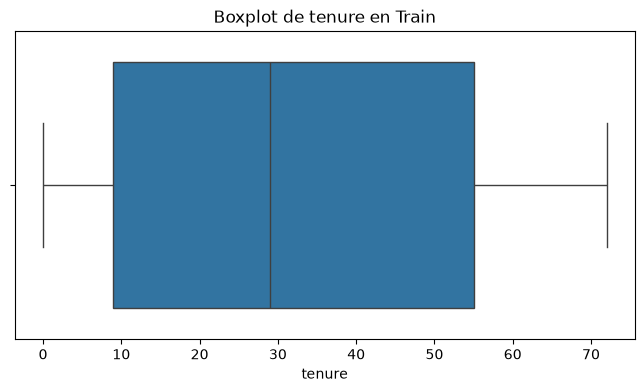

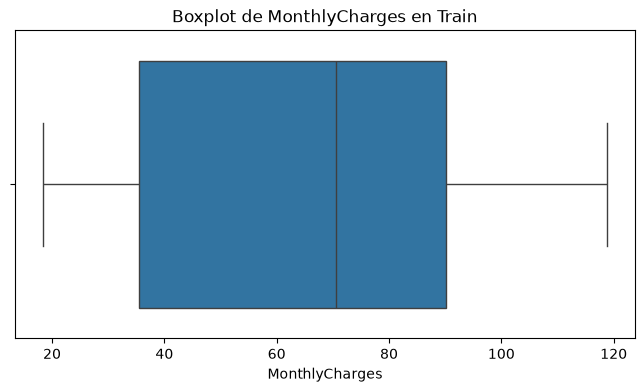

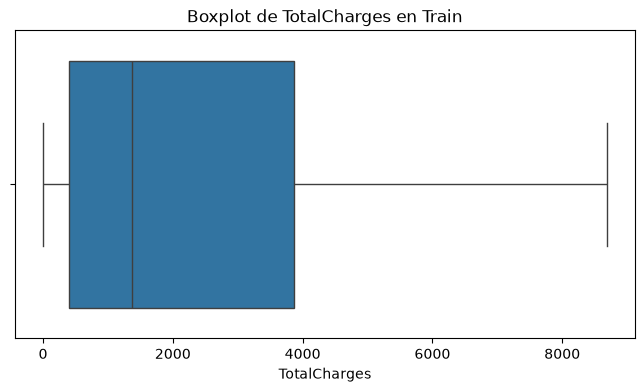

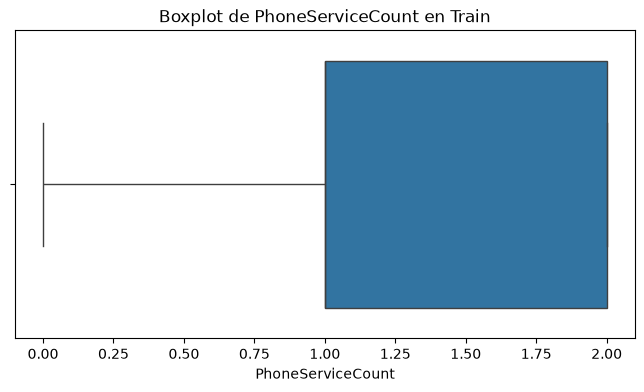

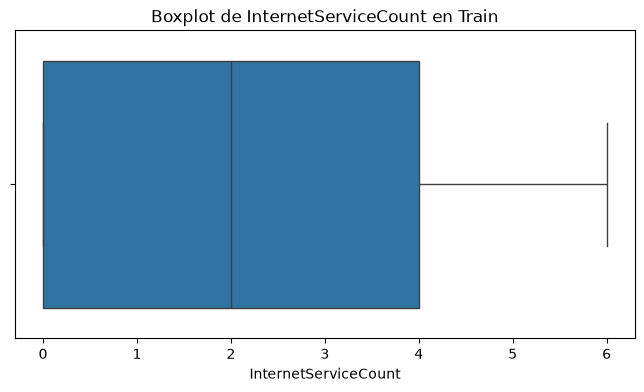

In [18]:
numeric_columns = [
    "tenure", "MonthlyCharges", "TotalCharges",
    "PhoneServiceCount", "InternetServiceCount"
]

X_train_original = X_train_raw.copy()
resultados_outliers = {}

for col in numeric_columns:
    q1 = X_train_raw[col].quantile(0.25)
    q3 = X_train_raw[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    cantidad = ((X_train_raw[col] < limite_inferior) |
                (X_train_raw[col] > limite_superior)).sum()

    resultados_outliers[col] = cantidad
    print("Variable:", col)
    print("Límites IQR:", round(limite_inferior, 2), "a", round(limite_superior, 2))
    print("Cantidad de posibles outliers:", cantidad)
    print("--------------------------------")

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=X_train_raw[col])
    plt.title("Boxplot de " + col + " en Train")
    plt.show()


In [19]:
for col in numeric_columns:
    print("Variable:", col)
    print("Mínimo:", X_train_original[col].min())
    print("Máximo:", X_train_original[col].max())
    print("--------------------------------")


Variable: tenure
Mínimo: 0
Máximo: 72
--------------------------------
Variable: MonthlyCharges
Mínimo: 18.4
Máximo: 118.75
--------------------------------
Variable: TotalCharges
Mínimo: 0.0
Máximo: 8684.8
--------------------------------
Variable: PhoneServiceCount
Mínimo: 0
Máximo: 2
--------------------------------
Variable: InternetServiceCount
Mínimo: 0
Máximo: 6
--------------------------------


Los rangos observados son coherentes con el significado de las variables: `tenure` va de 0 a 72 meses, `PhoneServiceCount` de 0 a 2, `InternetServiceCount` de 0 a 6, y los cargos también se encuentran dentro de valores razonables para el dataset. Por eso no eliminamos ninguna observación.

Este análisis usa solamente Train. Aunque el criterio de IQR marcara algún valor como extremo en un conteo discreto, no lo eliminaríamos si de todos modos está dentro de su rango válido: no sería un error de carga, sino una combinación de servicios perfectamente posible.

### Tipos de variables para el modelo

- **Numéricas:** `tenure`, `MonthlyCharges`, `TotalCharges`, `PhoneServiceCount` e `InternetServiceCount`. Los dos conteos solo aparecen en las Opciones 3 y 4.
- **Binarias:** `gender`, `SeniorCitizen`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `PaperlessBilling`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, más las dos variables de comportamiento (`FibraOptica_Contrato_mensual` y `Adulto_mayor_Pago_Mensual`) en las Opciones 2 y 4.
- **Categóricas nominales:** `InternetService`, `Contract` y `PaymentMethod`.

`InternetService` se mantiene en las cuatro opciones porque, aunque `InternetServiceCount` indica cuántos adicionales tiene un cliente, no distingue si su conexión es DSL, fibra óptica o ninguna, y en los gráficos exploratorios vimos que esa diferencia es relevante para el Churn.


### One-Hot Encoding

KNN necesita trabajar con números, y `InternetService`, `Contract` y `PaymentMethod` son categorías sin un orden natural entre sí. Por eso usamos One-Hot Encoding, que crea una columna binaria por categoría en lugar de inventar una escala que no existe.

El encoder hace `fit` únicamente con `X_train_raw`, y después se usa para transformar Train y Validation. Usamos `handle_unknown="ignore"` para poder transformar más adelante Test aunque apareciera allí alguna categoría no vista en Train.


In [20]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=np.int64
)

encoder.fit(X_train_raw[categorical_columns])
encoded_columns = encoder.get_feature_names_out(categorical_columns)

X_train_encoded = pd.DataFrame(
    encoder.transform(X_train_raw[categorical_columns]),
    columns=encoded_columns,
    index=X_train_raw.index
)
X_val_encoded = pd.DataFrame(
    encoder.transform(X_val_raw[categorical_columns]),
    columns=encoded_columns,
    index=X_val_raw.index
)

X_train_preprocessed = pd.concat([
    X_train_raw.drop(columns=categorical_columns), X_train_encoded
], axis=1)
X_val_preprocessed = pd.concat([
    X_val_raw.drop(columns=categorical_columns), X_val_encoded
], axis=1)

print("Columnas creadas por One-Hot Encoding:")
print(encoded_columns)


Columnas creadas por One-Hot Encoding:
['InternetService_DSL' 'InternetService_Fiber optic' 'InternetService_No'
 'Contract_Month-to-month' 'Contract_One year' 'Contract_Two year'
 'PaymentMethod_Bank transfer (automatic)'
 'PaymentMethod_Credit card (automatic)' 'PaymentMethod_Electronic check'
 'PaymentMethod_Mailed check']


### Escalado de las variables numéricas

KNN calcula distancias, por lo que si no escalamos, `TotalCharges`, que puede tomar valores de miles, tendría un peso mucho mayor que las variables 0/1 o los conteos pequeños. StandardScaler aprende la media y el desvío de las cinco variables numéricas únicamente en Train, y Validation se transforma con esos mismos parámetros mediante `transform`.

No escalamos las columnas binarias ni las creadas por One-Hot Encoding. Test todavía no se transforma.


In [21]:
scaler = StandardScaler()

X_train_preprocessed[numeric_columns] = scaler.fit_transform(
    X_train_preprocessed[numeric_columns]
)
X_val_preprocessed[numeric_columns] = scaler.transform(
    X_val_preprocessed[numeric_columns]
)


In [22]:
print("Resumen del escalado en Train:")
print(X_train_preprocessed[numeric_columns].agg(["mean", "std"]))

print("\nMismas columnas en Train y Validation:")
print(X_train_preprocessed.columns.equals(X_val_preprocessed.columns))
print("NaN en Train:", X_train_preprocessed.isna().sum().sum())
print("NaN en Validation:", X_val_preprocessed.isna().sum().sum())
print("Test continúa reservado sin transformar:", X_test_raw.shape)


Resumen del escalado en Train:
            tenure  MonthlyCharges  TotalCharges  PhoneServiceCount  \
mean -1.252910e-16   -4.498703e-17 -3.615780e-17       1.669145e-16   
std   1.000118e+00    1.000118e+00  1.000118e+00       1.000118e+00   

      InternetServiceCount  
mean          4.456659e-17  
std           1.000118e+00  

Mismas columnas en Train y Validation:
True
NaN en Train: 0
NaN en Validation: 0
Test continúa reservado sin transformar: (1409, 23)


## Feature Engineering y Feature Selection

Probamos cuatro formas distintas de representar a cada cliente. No supusimos de antemano que agregar o resumir variables iba a mejorar a KNN, ya que cada representación modifica de manera distinta las distancias entre clientes:

1. **Opción 1, Originales:** todas las variables originales, después del encoding.
2. **Opción 2, Originales + nuevas:** la Opción 1 más `FibraOptica_Contrato_mensual` y `Adulto_mayor_Pago_Mensual`, sin eliminar nada.
3. **Opción 3, Servicios agrupados:** reemplaza ocho variables individuales por los dos conteos (`PhoneServiceCount` e `InternetServiceCount`), y mantiene el resto.
4. **Opción 4, Agrupadas + nuevas:** Opción 3 más las dos variables de comportamiento.

Dentro de cada opción comparamos tres alternativas: todas sus features, Sequential Feature Selection Forward y Sequential Feature Selection Backward. De esta manera, si seleccionar variables no mejora el resultado en algún caso, la versión completa puede seguir ganando.

In [23]:
# Pasamos las listas definidas para cada opción a los nombres posteriores al encoding.
original_encoded_features = [
    col for col in X_train_preprocessed.columns
    if col not in count_columns + interaction_columns
]

grouped_encoded_features = [
    col for col in original_encoded_features
    if col not in redundant_service_columns
] + count_columns

features_por_opcion = {
    "Opción 1": original_encoded_features,
    "Opción 2": original_encoded_features + interaction_columns,
    "Opción 3": grouped_encoded_features,
    "Opción 4": grouped_encoded_features + interaction_columns
}

X_train_representaciones = {}
X_val_representaciones = {}

for opcion, features in features_por_opcion.items():
    X_train_representaciones[opcion] = X_train_preprocessed[features].copy()
    X_val_representaciones[opcion] = X_val_preprocessed[features].copy()
    print(opcion, "- cantidad inicial:", len(features))

print("\nControl de redundancia en Opción 3:")
print("Variables resumidas presentes:", [
    col for col in redundant_service_columns
    if col in features_por_opcion["Opción 3"]
])
print("Se mantiene InternetService:", any(
    col.startswith("InternetService_")
    for col in features_por_opcion["Opción 3"]
))


Opción 1 - cantidad inicial: 26
Opción 2 - cantidad inicial: 28
Opción 3 - cantidad inicial: 20
Opción 4 - cantidad inicial: 22

Control de redundancia en Opción 3:
Variables resumidas presentes: []
Se mantiene InternetService: True


### Cantidad de features y diferencia entre Forward y Backward

No usamos el mismo número fijo de variables en todos los grupos: elegimos aproximadamente la mitad de las disponibles en cada uno, 13 de 26 en la Opción 1, 14 de 28 en la Opción 2, 10 de 20 en la Opción 3 y 11 de 22 en la Opción 4. Nos pareció una reducción intermedia razonable, y mantener la misma proporción evita favorecer artificialmente a una representación.

Forward comienza sin ninguna feature y agrega, de a una, las que producen la mayor mejora en Balanced Accuracy dentro de folds internos de Train. Backward comienza con todas y elimina, de a una, las menos útiles. Como recorren caminos distintos, pueden llegar a subconjuntos diferentes aunque terminen con la misma cantidad de variables.

Los ocho selectores se ajustan solamente con Train (`cv=5` dentro de Train). Después entrenamos un KNN con cada subconjunto y calculamos Balanced Accuracy en Validation, y también evaluamos las cuatro versiones completas para tener con qué comparar.

In [24]:
n_features_to_select = {
    "Opción 1": 13,
    "Opción 2": 14,
    "Opción 3": 10,
    "Opción 4": 11
}

resultados = []
datos_alternativas = {}
selectores = {}

# Preparamos los folds internos ajustando encoder y scaler en cada Train fold.
cv_selector = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
folds_selector = []

for train_idx_selector, val_idx_selector in cv_selector.split(
    X_train_raw, y_train
):
    X_raw_train_selector = X_train_raw.iloc[train_idx_selector].copy()
    X_raw_val_selector = X_train_raw.iloc[val_idx_selector].copy()
    y_train_selector = y_train.iloc[train_idx_selector]
    y_val_selector = y_train.iloc[val_idx_selector]

    encoder_selector = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.int64
    )
    encoder_selector.fit(
        X_raw_train_selector[categorical_columns]
    )
    encoded_columns_selector = encoder_selector.get_feature_names_out(
        categorical_columns
    )

    train_encoded_selector = pd.DataFrame(
        encoder_selector.transform(
            X_raw_train_selector[categorical_columns]
        ),
        columns=encoded_columns_selector,
        index=X_raw_train_selector.index
    )
    val_encoded_selector = pd.DataFrame(
        encoder_selector.transform(
            X_raw_val_selector[categorical_columns]
        ),
        columns=encoded_columns_selector,
        index=X_raw_val_selector.index
    )

    X_train_selector = pd.concat([
        X_raw_train_selector.drop(columns=categorical_columns),
        train_encoded_selector
    ], axis=1)
    X_val_selector = pd.concat([
        X_raw_val_selector.drop(columns=categorical_columns),
        val_encoded_selector
    ], axis=1)

    scaler_selector = StandardScaler()
    X_train_selector[numeric_columns] = scaler_selector.fit_transform(
        X_train_selector[numeric_columns]
    )
    X_val_selector[numeric_columns] = scaler_selector.transform(
        X_val_selector[numeric_columns]
    )

    folds_selector.append((
        X_train_selector,
        X_val_selector,
        y_train_selector,
        y_val_selector
    ))


def evaluar_features_cv(features):
    puntajes = []
    for X_fold_train, X_fold_val, y_fold_train, y_fold_val in folds_selector:
        knn_fold_selector = KNeighborsClassifier(n_neighbors=5)
        knn_fold_selector.fit(X_fold_train[features], y_fold_train)
        pred_fold_selector = knn_fold_selector.predict(
            X_fold_val[features]
        )
        puntajes.append(balanced_accuracy_score(
            y_fold_val, pred_fold_selector
        ))
    return np.mean(puntajes)


def seleccionar_features(features_iniciales, cantidad, direccion):
    if direccion == "forward":
        seleccionadas = []
        restantes = features_iniciales.copy()
        while len(seleccionadas) < cantidad:
            mejor_feature = None
            mejor_puntaje = -np.inf
            for feature in restantes:
                puntaje = evaluar_features_cv(
                    seleccionadas + [feature]
                )
                if puntaje > mejor_puntaje:
                    mejor_puntaje = puntaje
                    mejor_feature = feature
            seleccionadas.append(mejor_feature)
            restantes.remove(mejor_feature)
        return seleccionadas

    seleccionadas = features_iniciales.copy()
    while len(seleccionadas) > cantidad:
        feature_a_eliminar = None
        mejor_puntaje = -np.inf
        for feature in seleccionadas:
            candidatas = [
                col for col in seleccionadas if col != feature
            ]
            puntaje = evaluar_features_cv(candidatas)
            if puntaje > mejor_puntaje:
                mejor_puntaje = puntaje
                feature_a_eliminar = feature
        seleccionadas.remove(feature_a_eliminar)
    return seleccionadas


for opcion in ["Opción 1", "Opción 2", "Opción 3", "Opción 4"]:
    X_train_opcion = X_train_representaciones[opcion]
    X_val_opcion = X_val_representaciones[opcion]

    # Primero evaluamos todas las variables del grupo.
    knn_todas = KNeighborsClassifier(n_neighbors=5)
    knn_todas.fit(X_train_opcion, y_train)
    pred_todas = knn_todas.predict(X_val_opcion)
    features_todas = X_train_opcion.columns.tolist()

    resultados.append({
        "Opción": opcion,
        "Método": "Todas",
        "Cantidad de features": len(features_todas),
        "Balanced Accuracy Validation": balanced_accuracy_score(y_val, pred_todas),
        "Features": features_todas
    })
    datos_alternativas[(opcion, "Todas")] = {
        "train": X_train_opcion.copy(),
        "validation": X_val_opcion.copy(),
        "features": features_todas
    }

    # Después ejecutamos Forward y Backward dentro del mismo grupo.
    for metodo, direccion in [("Forward", "forward"), ("Backward", "backward")]:
        selected_features = seleccionar_features(
            X_train_opcion.columns.tolist(),
            n_features_to_select[opcion],
            direccion
        )

        X_train_selected = X_train_opcion[selected_features].copy()
        X_val_selected = X_val_opcion[selected_features].copy()

        knn_selected = KNeighborsClassifier(n_neighbors=5)
        knn_selected.fit(X_train_selected, y_train)
        pred_selected = knn_selected.predict(X_val_selected)

        resultados.append({
            "Opción": opcion,
            "Método": metodo,
            "Cantidad de features": len(selected_features),
            "Balanced Accuracy Validation": balanced_accuracy_score(
                y_val, pred_selected
            ),
            "Features": selected_features
        })
        datos_alternativas[(opcion, metodo)] = {
            "train": X_train_selected,
            "validation": X_val_selected,
            "features": selected_features
        }
        selectores[(opcion, metodo)] = selected_features.copy()

        print(opcion, metodo, "terminado")


Opción 1 Forward terminado
Opción 1 Backward terminado
Opción 2 Forward terminado
Opción 2 Backward terminado
Opción 3 Forward terminado
Opción 3 Backward terminado
Opción 4 Forward terminado
Opción 4 Backward terminado


In [25]:
comparacion_alternativas = pd.DataFrame(resultados)

resumen_comparacion = comparacion_alternativas[
    ["Opción", "Método", "Cantidad de features", "Balanced Accuracy Validation"]
].copy()

display(resumen_comparacion.round(4))

print("Listas de variables de las ocho selecciones:")
for _, fila in comparacion_alternativas[
    comparacion_alternativas["Método"] != "Todas"
].iterrows():
    print("\n" + fila["Opción"] + " - " + fila["Método"])
    print("Cantidad:", fila["Cantidad de features"])
    for feature in fila["Features"]:
        print("-", feature)


,Opción,Método,Cantidad de features,Balanced Accuracy Validation
0,Opción 1,Todas,26,0.7050
1,Opción 1,Forward,13,0.7240
2,Opción 1,Backward,13,0.6704
3,Opción 2,Todas,28,0.7061
4,Opción 2,Forward,14,0.7240
5,Opción 2,Backward,14,0.6961
6,Opción 3,Todas,20,0.6941
7,Opción 3,Forward,10,0.7013
8,Opción 3,Backward,10,0.7070
9,Opción 4,Todas,22,0.6937


Listas de variables de las ocho selecciones:

Opción 1 - Forward
Cantidad: 13
- Contract_Month-to-month
- InternetService_Fiber optic
- Partner
- InternetService_DSL
- PhoneService
- InternetService_No
- Contract_One year
- Contract_Two year
- PaymentMethod_Credit card (automatic)
- OnlineBackup
- OnlineSecurity
- TechSupport
- StreamingTV

Opción 1 - Backward
Cantidad: 13
- gender
- Dependents
- tenure
- MultipleLines
- DeviceProtection
- TechSupport
- StreamingTV
- PaperlessBilling
- InternetService_DSL
- InternetService_Fiber optic
- Contract_Month-to-month
- PaymentMethod_Bank transfer (automatic)
- PaymentMethod_Mailed check

Opción 2 - Forward
Cantidad: 14
- Contract_Month-to-month
- InternetService_Fiber optic
- Partner
- InternetService_DSL
- PhoneService
- InternetService_No
- FibraOptica_Contrato_mensual
- Contract_One year
- Contract_Two year
- PaymentMethod_Credit card (automatic)
- OnlineBackup
- OnlineSecurity
- TechSupport
- StreamingTV

Opción 2 - Backward
Cantidad: 14


### Elección automática y métrica utilizada

Para elegir entre las doce alternativas usamos **Balanced Accuracy en Validation**. Esta métrica promedia el porcentaje de aciertos entre los clientes con Churn y los que no, de manera que ambas clases pesan lo mismo aunque haya muchos más casos de No Churn.

Nos pareció el criterio más adecuado justamente porque el dataset está desbalanceado (73,5 % No Churn frente a 26,5 % Churn). Si mirásemos solo Accuracy, una alternativa podría parecer buena únicamente por acertar bien en la clase mayoritaria, aunque detectara pocos abandonos reales. De hecho, más adelante vemos que un modelo naive que siempre predice No Churn ya alcanza un Accuracy cercano a 73,5 % sin aprender nada.

Tampoco elegimos por Precision o Recall de manera aislada, porque cada una prioriza un objetivo distinto: Precision importa más si contactar clientes tiene un costo y queremos evitar falsos positivos, y Recall importa más si lo más costoso es dejar sin detectar a un cliente que efectivamente va a abandonar. F1-Score combina ambas, pero no considera directamente el acierto sobre No Churn.

Balanced Accuracy nos permite hacer esta primera comparación entre representaciones sin decidir todavía qué tipo de error es más importante, algo que definimos más adelante al comparar el modelo base con Oversampling.

Elegimos automáticamente la fila con mayor Balanced Accuracy entre las cuatro versiones completas y las ocho selecciones, mirando exclusivamente Validation. No usamos Test para desempatar ni para confirmar la elección. Si una versión con todas las variables hubiera obtenido el mejor resultado, la habríamos conservado, ya que Feature Selection es un experimento y no una obligación.

In [26]:
indice_mejor = comparacion_alternativas[
    "Balanced Accuracy Validation"
].idxmax()
mejor_fila = comparacion_alternativas.loc[indice_mejor]

opcion_ganadora = mejor_fila["Opción"]
metodo_ganador = mejor_fila["Método"]
mejor_alternativa = opcion_ganadora + " - " + metodo_ganador
mejor_balanced_accuracy_validation = mejor_fila[
    "Balanced Accuracy Validation"
]
mejores_features = mejor_fila["Features"]

X_train = datos_alternativas[
    (opcion_ganadora, metodo_ganador)
]["train"].copy()
X_val = datos_alternativas[
    (opcion_ganadora, metodo_ganador)
]["validation"].copy()

print("Mejor alternativa en Validation:", mejor_alternativa)
print("Balanced Accuracy en Validation:", round(mejor_balanced_accuracy_validation, 4))
print("Cantidad final de variables:", len(mejores_features))
print("Variables finales:")
for feature in mejores_features:
    print("-", feature)


Mejor alternativa en Validation: Opción 1 - Forward
Balanced Accuracy en Validation: 0.724
Cantidad final de variables: 13
Variables finales:
- Contract_Month-to-month
- InternetService_Fiber optic
- Partner
- InternetService_DSL
- PhoneService
- InternetService_No
- Contract_One year
- Contract_Two year
- PaymentMethod_Credit card (automatic)
- OnlineBackup
- OnlineSecurity
- TechSupport
- StreamingTV


### Resultado de la comparación

Al aplicar el criterio automático de mayor Balanced Accuracy en Validation, la alternativa guardada fue **Opción 1 - Forward**. Esta es la alternativa que se utiliza en K-Fold, el entrenamiento final, la evaluación de Test y el experimento de Oversampling.

Forward partió sin variables y fue incorporando las que producían el mejor resultado promedio dentro de los folds internos de Train, hasta alcanzar la cantidad definida para la Opción 1. Las variables seleccionadas se muestran en la salida anterior.

Opción 2 - Forward obtuvo un resultado prácticamente igual al de la alternativa elegida. Como la selección automática utiliza `idxmax()`, si los mejores resultados son iguales toma la primera fila que alcanza el máximo. En esta ejecución, por lo tanto, se conservó Opción 1 - Forward sin utilizar Test para desempatar ni confirmar la elección.

Los resultados también muestran que Feature Selection no necesariamente mejora el modelo. Dependiendo de la representación utilizada, Forward o Backward pueden obtener un resultado mejor o peor que la versión con todas las variables. Por eso no asumimos de antemano que reducir la cantidad de features sea beneficioso, sino que comparamos todas las alternativas mediante Balanced Accuracy en Validation.

### Control explícito de Data Leakage

- Los índices de Train, Validation y Test se reservaron antes de analizar las combinaciones de Churn.
- Las variables relacionadas con Churn se definieron observando únicamente Train y después se calcularon fila por fila.
- Las columnas redundantes de las Opciones 3 y 4 se definieron sin consultar Validation ni Test.
- El encoder y el scaler hicieron `fit` solamente con Train.
- En Feature Selection, cada fold interno ajustó su propio encoder, scaler y KNN utilizando exclusivamente su Train fold.
- Validation se utilizó para comparar las doce alternativas y elegir una.
- Test permaneció guardado como `X_test_raw`: no se transformó, no se usó para seleccionar variables y no influyó en la elección.

Por lo tanto, ninguna observación de Test influyó en el preprocessing, la selección de features ni la elección del modelo.

### Preparación de Test después de la elección

Recién en este punto transformamos Test, utilizando el encoder y el scaler ya ajustados en Train, sin realizar ningún `fit` nuevo, y nos quedamos con las columnas correspondientes a la alternativa ganadora.

In [27]:
X_test_encoded = pd.DataFrame(
    encoder.transform(X_test_raw[categorical_columns]),
    columns=encoded_columns,
    index=X_test_raw.index
)
X_test_preprocessed = pd.concat([
    X_test_raw.drop(columns=categorical_columns), X_test_encoded
], axis=1)
X_test_preprocessed[numeric_columns] = scaler.transform(
    X_test_preprocessed[numeric_columns]
)

X_test = X_test_preprocessed[mejores_features].copy()

print("Train final:", X_train.shape)
print("Validation final:", X_val.shape)
print("Test final:", X_test.shape)
print("Mismas columnas:", X_train.columns.equals(X_test.columns))
print("NaN en Test:", X_test.isna().sum().sum())


Train final: (4225, 13)
Validation final: (1409, 13)
Test final: (1409, 13)
Mismas columnas: True
NaN en Test: 0


### Unión de Train y Validation

Una vez elegida la alternativa, unimos Train y Validation para entrenar el modelo final con más datos. Ambos conjuntos ya estaban transformados con el encoder y el scaler ajustados en el Train original. Test no se concatena.

In [28]:
X_train_val = pd.concat([X_train, X_val]).reset_index(drop=True)
y_train_val = pd.concat([y_train, y_val]).reset_index(drop=True)

print("Train + Validation:", X_train_val.shape)
print("Test reservado para evaluación final:", X_test.shape)


Train + Validation: (5634, 13)
Test reservado para evaluación final: (1409, 13)


## 3. Stratified K-Fold Cross-Validation

Aplicamos 5 folds estratificados sobre Train + Validation, utilizando la representación y las features que ya habían ganado. Esta etapa no vuelve a seleccionar variables ni consulta Test; describe qué tan estable resulta la alternativa elegida.

Para evitar fuga de información entre folds, en cada iteración el encoder y el scaler se ajustan nuevamente solo con las filas de entrenamiento de ese fold, y luego transforman su fold de validación. Las columnas finales permanecen fijas, porque ya fueron elegidas antes, con el holdout Train/Validation.


In [29]:
X_train_val_raw = pd.concat([X_train_raw, X_val_raw]).reset_index(drop=True)
y_train_val_cv = pd.concat([y_train, y_val]).reset_index(drop=True)

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
balanced_accuracies = []

for numero_fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train_val_raw, y_train_val_cv), start=1
):
    X_raw_fold_train = X_train_val_raw.iloc[train_idx].copy()
    X_raw_fold_val = X_train_val_raw.iloc[val_idx].copy()
    y_fold_train = y_train_val_cv.iloc[train_idx]
    y_fold_val = y_train_val_cv.iloc[val_idx]

    encoder_fold = OneHotEncoder(
        handle_unknown="ignore", sparse_output=False, dtype=np.int64
    )
    encoder_fold.fit(X_raw_fold_train[categorical_columns])
    fold_encoded_columns = encoder_fold.get_feature_names_out(categorical_columns)

    train_encoded_fold = pd.DataFrame(
        encoder_fold.transform(X_raw_fold_train[categorical_columns]),
        columns=fold_encoded_columns,
        index=X_raw_fold_train.index
    )
    val_encoded_fold = pd.DataFrame(
        encoder_fold.transform(X_raw_fold_val[categorical_columns]),
        columns=fold_encoded_columns,
        index=X_raw_fold_val.index
    )

    X_fold_train = pd.concat([
        X_raw_fold_train.drop(columns=categorical_columns), train_encoded_fold
    ], axis=1)
    X_fold_val = pd.concat([
        X_raw_fold_val.drop(columns=categorical_columns), val_encoded_fold
    ], axis=1)

    scaler_fold = StandardScaler()
    X_fold_train[numeric_columns] = scaler_fold.fit_transform(
        X_fold_train[numeric_columns]
    )
    X_fold_val[numeric_columns] = scaler_fold.transform(
        X_fold_val[numeric_columns]
    )

    # reindex asegura las mismas columnas incluso si una categoría faltara en un fold.
    X_fold_train = X_fold_train.reindex(columns=mejores_features, fill_value=0)
    X_fold_val = X_fold_val.reindex(columns=mejores_features, fill_value=0)

    knn_fold = KNeighborsClassifier(n_neighbors=5)
    knn_fold.fit(X_fold_train, y_fold_train)
    pred_fold = knn_fold.predict(X_fold_val)
    balanced_fold = balanced_accuracy_score(y_fold_val, pred_fold)
    balanced_accuracies.append(balanced_fold)

    print("Fold", numero_fold, "- Balanced Accuracy:", round(balanced_fold, 4))

print("Balanced Accuracy promedio:", round(np.mean(balanced_accuracies), 4))
print("Desvío entre folds:", round(np.std(balanced_accuracies), 4))


Fold 1 - Balanced Accuracy: 0.6806
Fold 2 - Balanced Accuracy: 0.6592
Fold 3 - Balanced Accuracy: 0.6963
Fold 4 - Balanced Accuracy: 0.7107
Fold 5 - Balanced Accuracy: 0.7178
Balanced Accuracy promedio: 0.6929
Desvío entre folds: 0.0211


#### ¿Por qué usar Stratified K-Fold?

Un único holdout puede depender bastante de qué clientes terminaron en cada conjunto. Con 5 folds, cada observación participa una vez en validación y cuatro veces en entrenamiento, lo que ofrece un panorama más completo. La estratificación mantiene además una proporción de Churn similar en cada fold, algo importante dado que la clase positiva es minoritaria.

Seguimos usando Balanced Accuracy como métrica principal: el promedio resume el desempeño general, y el desvío indica cuánto varía entre particiones. Test no participa de esta etapa.


## 4. Evaluación final del modelo base

Con la representación y las features ya decididas, entrenamos el KNN final utilizando Train y Validation juntos, y lo evaluamos en Test una única vez, sobre clientes que no participaron en ninguna decisión previa.

In [30]:
knn_final = KNeighborsClassifier(n_neighbors=5)
knn_final.fit(X_train_val, y_train_val)

y_pred_test = knn_final.predict(X_test)

matriz_confusion = confusion_matrix(y_test, y_pred_test)
accuracy_knn = accuracy_score(y_test, y_pred_test)
precision_knn = precision_score(y_test, y_pred_test)
recall_knn = recall_score(y_test, y_pred_test)
f1_knn = f1_score(y_test, y_pred_test)
balanced_accuracy_knn = balanced_accuracy_score(y_test, y_pred_test)

print("Alternativa elegida:", mejor_alternativa)
print("Cantidad de variables:", X_train_val.shape[1])
print("Matriz de Confusión:")
print(matriz_confusion)
print("Accuracy:", round(accuracy_knn, 4))
print("Precision:", round(precision_knn, 4))
print("Recall:", round(recall_knn, 4))
print("F1-Score:", round(f1_knn, 4))
print("Balanced Accuracy:", round(balanced_accuracy_knn, 4))


Alternativa elegida: Opción 1 - Forward
Cantidad de variables: 13
Matriz de Confusión:
[[867 168]
 [175 199]]
Accuracy: 0.7566
Precision: 0.5422
Recall: 0.5321
F1-Score: 0.5371
Balanced Accuracy: 0.6849


### Matriz de Confusión

La matriz compara la clase real con la predicción. Consideramos `Churn = 1` como la clase positiva:

- **Verdaderos negativos:** clientes que no abandonaron y fueron clasificados correctamente.
- **Falsos positivos:** clientes que no abandonaron, pero el modelo predijo Churn.
- **Falsos negativos:** clientes que abandonaron, pero el modelo no los detectó.
- **Verdaderos positivos:** clientes que abandonaron y fueron detectados correctamente.

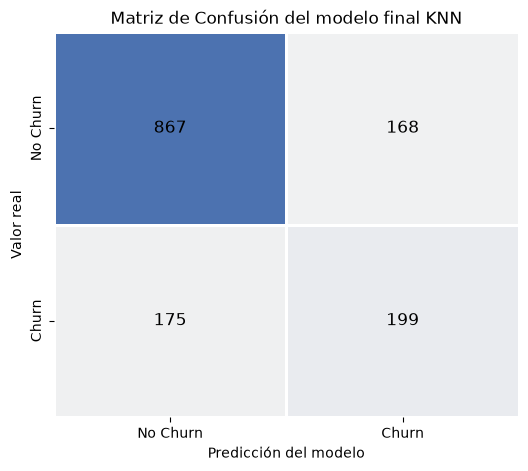

In [31]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_confusion,
    annot=False,
    cmap=sns.light_palette("#4C72B0", as_cmap=True),
    cbar=False,
    linewidths=1,
    linecolor="white",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

for fila in range(matriz_confusion.shape[0]):
    for columna in range(matriz_confusion.shape[1]):
        plt.text(
            columna + 0.5,
            fila + 0.5,
            matriz_confusion[fila, columna],
            ha="center",
            va="center",
            color="black",
            fontsize=12
        )

plt.title("Matriz de Confusión del modelo final KNN")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.show()

### Significado de las métricas

- **Accuracy:** proporción total de clientes clasificados correctamente.
- **Precision:** entre los clientes que el modelo marcó como posibles casos de Churn, indica qué proporción realmente abandonó. Es relevante si contactar u ofrecer descuentos tiene un costo.
- **Recall:** entre los clientes que realmente abandonaron, indica qué proporción fue detectada. Un Recall bajo deja muchos abandonos sin identificar.
- **F1-Score:** resume el equilibrio entre Precision y Recall.
- **Balanced Accuracy:** promedia el acierto sobre Churn y sobre No Churn, de manera que ambas clases pesan por igual.

Accuracy no debe analizarse de manera aislada: una proporción alta de No Churn permite que un modelo parezca acertado simplemente por favorecer a la clase mayoritaria. Por eso lo comparamos con un modelo naive y observamos también Recall, F1-Score y Balanced Accuracy.

### Comparación con un modelo naive

Calculamos el Accuracy de un modelo naive que predice sobre Test la clase mayoritaria identificada en Train + Validation. Este baseline muestra qué resultado puede obtenerse sin aprender ningún patrón. Nuestro KNN debería superar ese punto de referencia y, además, detectar una parte útil de los clientes con Churn.

In [32]:
clase_mayoritaria = y_train_val.value_counts().idxmax()
y_pred_naive = np.full(len(y_test), clase_mayoritaria)
accuracy_naive = accuracy_score(y_test, y_pred_naive)

print("Distribución de Churn en Test:")
print(y_test.value_counts(normalize=True))
print()
print("Clase mayoritaria:", clase_mayoritaria)
print("Accuracy del KNN:", round(accuracy_knn, 4))
print("Accuracy del modelo naive:", round(accuracy_naive, 4))
print("Diferencia de Accuracy:", round(accuracy_knn - accuracy_naive, 4))

Distribución de Churn en Test:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64

Clase mayoritaria: 0
Accuracy del KNN: 0.7566
Accuracy del modelo naive: 0.7346
Diferencia de Accuracy: 0.022


### Conclusión del modelo base

La alternativa elegida fue **Opción 1 - Forward**. La decisión se tomó con Balanced Accuracy porque buscábamos un criterio equilibrado entre Churn y No Churn para comparar representaciones; esto no significa que Precision o Recall dejen de ser importantes, sino que la prioridad depende del uso concreto del modelo.

Los resultados de Stratified K-Fold muestran un desempeño relativamente consistente entre particiones, aunque existe cierta variación entre los folds.

En Test, la matriz de confusión muestra que el modelo clasifica correctamente a una gran parte de los clientes sin Churn y detecta una parte de quienes abandonan, aunque también produce falsos positivos y deja casos de Churn sin identificar.

El KNN supera al modelo naive por un margen moderado. Balanced Accuracy y Recall muestran con mayor claridad que todavía cuesta identificar a la clase minoritaria.

Todos estos cálculos utilizaron las variables seleccionadas por Forward dentro de la Opción 1, y Test se usó recién después de cerrar el preprocessing y la elección con Train/Validation.

## 5. Análisis de negocio e impacto de las métricas

Supongamos que Marketing va a utilizar las predicciones del modelo para ofrecer un descuento del 50 % durante 3 meses a los clientes que se prediga como posibles casos de Churn. Para evaluar una técnica frente al desbalance, construimos un segundo KNN aplicando Random Oversampling sobre Train + Validation.

La clase mayoritaria está formada por los clientes que no abandonan, y la minoritaria por quienes sí lo hacen. Undersampling también sería una opción, pero implicaría descartar clientes reales de la clase mayoritaria, perdiendo información sobre los casos de No Churn. Por eso preferimos Oversampling, que conserva todos los registros y repite observaciones de la clase minoritaria hasta equilibrar ambas clases. Esta técnica se aplica solamente al conjunto de entrenamiento; Test conserva su distribución real, porque necesitamos evaluar el modelo en condiciones similares a las que enfrentaría la empresa.

In [33]:


# Unimos las variables y el target para hacer oversampling solamente
# sobre Train + Validation.
train_val_oversampling = X_train_val.copy()
train_val_oversampling["Churn"] = y_train_val.values

clientes_no_churn = train_val_oversampling[train_val_oversampling["Churn"] == 0]

clientes_churn = train_val_oversampling[train_val_oversampling["Churn"] == 1]

print("Antes del oversampling:")
print(train_val_oversampling["Churn"].value_counts())

# Repetimos clientes de la clase minoritaria hasta igualar la mayoritaria.
clientes_churn_oversampling = resample(
    clientes_churn,
    replace=True,
    n_samples=len(clientes_no_churn),
    random_state=42
)

train_val_balanceado = pd.concat([
    clientes_no_churn,
    clientes_churn_oversampling
]).sample(frac=1, random_state=42).reset_index(drop=True)

X_train_val_balanceado = train_val_balanceado.drop(columns="Churn")
y_train_val_balanceado = train_val_balanceado["Churn"]

print("Después del oversampling:")
print(y_train_val_balanceado.value_counts())

Antes del oversampling:
Churn
0    4139
1    1495
Name: count, dtype: int64
Después del oversampling:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [34]:
# Entrenamos un segundo KNN con los datos balanceados.
knn_oversampling = KNeighborsClassifier(n_neighbors=5)
knn_oversampling.fit(
    X_train_val_balanceado,
    y_train_val_balanceado
)

y_pred_test_oversampling = knn_oversampling.predict(X_test)

matriz_oversampling = confusion_matrix(
    y_test,
    y_pred_test_oversampling
)
accuracy_oversampling = accuracy_score(
    y_test,
    y_pred_test_oversampling
)
precision_oversampling = precision_score(
    y_test,
    y_pred_test_oversampling
)
recall_oversampling = recall_score(
    y_test,
    y_pred_test_oversampling
)
f1_oversampling = f1_score(
    y_test,
    y_pred_test_oversampling
)
balanced_accuracy_oversampling = balanced_accuracy_score(
    y_test,
    y_pred_test_oversampling
)

print("Matriz de Confusión con Oversampling:")
print(matriz_oversampling)
print()
print("Accuracy:", round(accuracy_oversampling, 4))
print("Precision:", round(precision_oversampling, 4))
print("Recall:", round(recall_oversampling, 4))
print("F1-Score:", round(f1_oversampling, 4))
print("Balanced Accuracy:", round(balanced_accuracy_oversampling, 4))

Matriz de Confusión con Oversampling:
[[717 318]
 [101 273]]

Accuracy: 0.7026
Precision: 0.4619
Recall: 0.7299
F1-Score: 0.5658
Balanced Accuracy: 0.7114


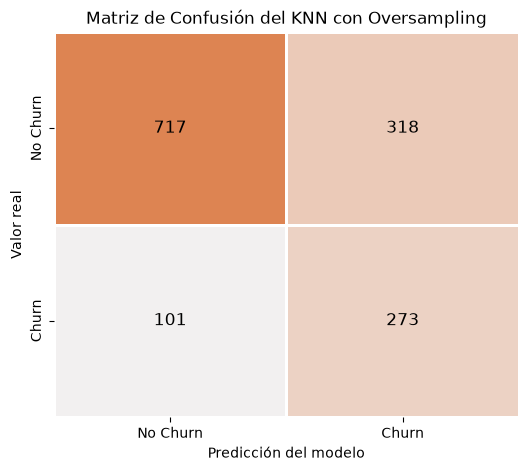

In [35]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_oversampling,
    annot=False,
    cmap=sns.light_palette("#DD8452", as_cmap=True),
    cbar=False,
    linewidths=1,
    linecolor="white",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

for fila in range(matriz_oversampling.shape[0]):
    for columna in range(matriz_oversampling.shape[1]):
        plt.text(
            columna + 0.5,
            fila + 0.5,
            matriz_oversampling[fila, columna],
            ha="center",
            va="center",
            color="black",
            fontsize=12
        )

plt.title("Matriz de Confusión del KNN con Oversampling")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.show()

In [36]:
comparacion_modelos = pd.DataFrame({
    "Modelo": ["KNN base", "KNN con Oversampling"],
    "Accuracy": [accuracy_knn, accuracy_oversampling],
    "Precision": [precision_knn, precision_oversampling],
    "Recall": [recall_knn, recall_oversampling],
    "F1-Score": [f1_knn, f1_oversampling],
    "Balanced Accuracy": [
        balanced_accuracy_knn,
        balanced_accuracy_oversampling
    ]
})

display(comparacion_modelos.round(4))

,Modelo,Accuracy,Precision,Recall,F1-Score,Balanced Accuracy
0,KNN base,0.7566,0.5422,0.5321,0.5371,0.6849
1,KNN con Oversampling,0.7026,0.4619,0.7299,0.5658,0.7114


### Interpretación de negocio

Al aplicar Oversampling con las mismas variables de la alternativa ganadora, el modelo detecta más clientes que abandonan que el modelo base.

Por eso aumentan Recall y Balanced Accuracy y disminuyen los falsos negativos. F1-Score también mejora, porque el aumento de Recall compensa parte de la pérdida de Precision.

La contrapartida es que aparecen más alertas incorrectas: aumentan los falsos positivos y disminuyen Precision y Accuracy. Oversampling, entonces, cambia el tipo de error que se prioriza.

Si el descuento es costoso, puede convenir el modelo base, porque evita más ofrecimientos innecesarios. Si perder un cliente resulta mucho más costoso que ofrecer el descuento, el modelo con Oversampling puede ser más útil, ya que detecta abandonos adicionales. Esta comparación muestra que no existe una única métrica correcta para todas las decisiones: Precision importa cuando preocupa contactar de más, mientras que Recall importa cuando preocupa no detectar un abandono.

# Parte II: Reformulando el problema

## Contratación de soporte técnico

Para esta segunda parte dejamos de lado `Churn` y buscamos otra pregunta que pudiera responderse con el mismo dataset. Retomando el análisis exploratorio del principio, en el gráfico de burbujas (donde combinamos cantidad de servicios, cargo mensual y Churn) `TechSupport` es uno de los servicios que componen `ServiceCount`, y ese gráfico ya había mostrado que la cantidad de servicios adicionales contratados se relaciona con el comportamiento del cliente. Esto nos llevó a pensar en los servicios adicionales como otra fuente de preguntas de negocio, más allá de predecir el abandono, y en particular a preguntarnos si se puede anticipar qué clientes van a contratar o no un servicio como soporte técnico.

La nueva variable objetivo es `TechSupport`:

- `TechSupport = 1`: el cliente tiene contratado soporte técnico.
- `TechSupport = 0`: el cliente tiene Internet, pero no contrató soporte técnico.

Al existir solo dos clases, sigue siendo un problema de clasificación binaria, como en la Parte I. Sin embargo, el enfoque de negocio cambia bastante: acá no se trata de frenar una fuga de clientes, sino de anticipar una venta. Si el modelo logra reconocer un perfil similar al de los clientes que ya tienen soporte técnico, la empresa podría usar esa información para orientar una campaña comercial hacia los clientes con mayor probabilidad de interés, en lugar de ofrecerlo indistintamente a todos.

Es importante interpretar esto con cuidado. Que un cliente figure con `TechSupport = 0` no significa que no le interese el servicio, y que el modelo lo clasifique como positivo tampoco demuestra intención de compra, solo indica una similitud con los patrones observados en clientes que actualmente lo tienen. Se trata de una aproximación útil para priorizar a quién contactar, no de una predicción de intención de compra.

### Población analizada y distribución del target

`TechSupport` es un servicio adicional de Internet, por lo que en los datos también aparece la categoría `No internet service`. Esta categoría no representa una decisión de no contratar soporte, sino que el cliente no tiene la posibilidad de contratarlo porque no posee Internet.

Por eso trabajamos únicamente con clientes cuyo `InternetService` es DSL o fibra óptica. De esta manera, la clase negativa queda bien definida: representa a clientes que podrían contratar soporte, pero actualmente no lo tienen. Esta decisión hace que el problema de negocio resulte más coherente, ya que no tendría demasiado sentido predecir que alguien sin Internet no va a contratar un servicio de Internet.

In [37]:
# TechSupport ya quedó transformada a 0 y 1 en el preprocessing anterior.
# Conservamos solamente clientes que tienen servicio de Internet.
df_support = df[df["InternetService"] != "No"].copy()

y_support = df_support["TechSupport"].astype("int64")

distribucion_support = pd.DataFrame({
    "Cantidad": y_support.value_counts().sort_index(),
    "Proporción": y_support.value_counts(normalize=True).sort_index()
})
distribucion_support.index = ["Sin TechSupport", "Con TechSupport"]

print("Clientes sin servicio de Internet excluidos:", len(df) - len(df_support))
print("Clientes incluidos en la Parte II:", len(df_support))
display(distribucion_support)

Clientes sin servicio de Internet excluidos: 1526
Clientes incluidos en la Parte II: 5517


,Cantidad,Proporción
Sin TechSupport,3473,0.629509
Con TechSupport,2044,0.370491


De los 5.517 clientes con servicio de Internet, 3.473 no tienen TechSupport y 2.044 sí lo tienen, lo que representa aproximadamente 62,95 % sin soporte y 37,05 % con soporte.

Las clases presentan un desbalance moderado: la clase negativa es más frecuente, pero la positiva conserva una cantidad suficiente de observaciones para entrenar y evaluar el modelo. De todos modos, un modelo podría favorecer a los clientes sin soporte y obtener un Accuracy aparentemente razonable. Por eso, nuevamente, no evaluamos solamente con Accuracy y también observamos Precision, Recall, F1-Score y Balanced Accuracy.


### Elección de las variables predictoras

Cambiar el target obliga a revisar qué información tiene sentido utilizar. Elegimos variables demográficas, antigüedad, tipo de conexión, contrato, medio de pago y otros servicios contratados, características que describen distintos perfiles de clientes sin contener directamente la respuesta.

Excluimos deliberadamente:

- `TechSupport`, porque ahora es el target.
- `ServiceCount`, porque fue construida sumando también `TechSupport`. Utilizarla implicaría incluir una parte del target dentro de una variable predictora.
- `InternetServiceCount`, por el mismo motivo, ya que también incluye a `TechSupport` en su cálculo.
- `MonthlyCharges` y `TotalCharges`, porque los cargos actuales pueden incluir el precio del propio soporte. Usarlas introduciría una relación circular: el modelo podría reconocer el cargo generado por un servicio ya contratado en lugar de aprender un perfil útil para ofrecerlo.
- `Churn`, porque pertenece al problema de la Parte I y no es necesaria para responder esta nueva pregunta.
- `customerID` y `TenureGroup`, porque son un identificador y una agrupación creada únicamente para una visualización.
- A su vez las variables binarias`FibraOptica_Contrato_mensual`y `Adulto_mayor_Pago_Mensual`, creadas para el modelado anterios tampoco seran utilizadas, ya que fueron construidas en base al analisis de datos enfocado en la variable  `Churn` y en este nuevo modelo dejan de tener sentido.

Los demás servicios de Internet, como seguridad, backup, protección de dispositivos o streaming, sí se conservan, ya que aunque puedan estar relacionados comercialmente con el soporte técnico, no se construyen a partir del target.


In [38]:
support_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

X_support = df_support[support_features].copy()

print("Cantidad de variables originales utilizadas:", len(support_features))
print("Variables predictoras:")
for feature in support_features:
    print("-", feature)

print()
print("¿TechSupport está entre las predictoras?", "TechSupport" in X_support.columns)
print("¿ServiceCount está entre las predictoras?", "ServiceCount" in X_support.columns)
print("InternetServiceCount está entre las predictoras?", "InternetServiceCount" in X_support.columns)
print("MonthlyCharges está entre las predictoras?", "MonthlyCharges" in X_support.columns)
print("TotalCharges está entre las predictoras?", "TotalCharges" in X_support.columns)
print("¿FibraOptica_Contrato_mensual está entre las predictoras?", "FibraOptica_Contrato_mensual" in X_support.columns)
print("¿Adulto_mayor_Pago_Mensual está entre las predictoras?", "Adulto_mayor_Pago_Mensual" in X_support.columns)

Cantidad de variables originales utilizadas: 16
Variables predictoras:
- gender
- SeniorCitizen
- Partner
- Dependents
- tenure
- PhoneService
- MultipleLines
- InternetService
- OnlineSecurity
- OnlineBackup
- DeviceProtection
- StreamingTV
- StreamingMovies
- Contract
- PaperlessBilling
- PaymentMethod

¿TechSupport está entre las predictoras? False
¿ServiceCount está entre las predictoras? False
InternetServiceCount está entre las predictoras? False
MonthlyCharges está entre las predictoras? False
TotalCharges está entre las predictoras? False
¿FibraOptica_Contrato_mensual está entre las predictoras? False
¿Adulto_mayor_Pago_Mensual está entre las predictoras? False


### Separación Train / Validation / Test

Mantenemos la misma lógica metodológica de la Parte I. Separamos 60 % de los clientes para Train, 20 % para Validation y 20 % para Test, utilizando `stratify` para conservar aproximadamente la proporción de clientes con y sin soporte en los tres conjuntos.

Train se utiliza para ajustar el encoder y el scaler. Validation permite observar el comportamiento del KNN antes del entrenamiento final. Test no participa en ninguna decisión y queda reservado para la última evaluación.

No volvimos a analizar la presencia de datos faltantes y outliers porque trabajamos con la misma base ya revisada en la Parte I. Las transformaciones fijas aplicadas sobre `df` se mantienen, y para este nuevo problema volvemos a realizar el split y a ajustar el encoder y el scaler solamente con Train.

In [39]:
X_train_support, X_temp_support, y_train_support, y_temp_support = train_test_split(
    X_support,
    y_support,
    test_size=0.40,
    random_state=42,
    stratify=y_support
)

X_val_support, X_test_support, y_val_support, y_test_support = train_test_split(
    X_temp_support,
    y_temp_support,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_support
)

print("Train:", X_train_support.shape)
print("Validation:", X_val_support.shape)
print("Test reservado:", X_test_support.shape)
print()
print("Proporción con TechSupport en Train:", round(y_train_support.mean(), 4))
print("Proporción con TechSupport en Validation:", round(y_val_support.mean(), 4))

Train: (3310, 16)
Validation: (1103, 16)
Test reservado: (1104, 16)

Proporción con TechSupport en Train: 0.3704
Proporción con TechSupport en Validation: 0.3708


### Preprocessing para KNN

`InternetService`, `Contract` y `PaymentMethod` son variables categóricas nominales, por lo que utilizamos One-Hot Encoding, igual que en la Parte I. El encoder se ajusta únicamente con Train y luego transforma Validation y Test.

La única variable numérica continua elegida es `tenure`, y la escalamos con StandardScaler para que su rango no domine a las variables binarias en el cálculo de distancias de KNN. El scaler también se ajusta solamente con Train. Las columnas binarias y las creadas por One-Hot Encoding permanecen como 0 y 1.

In [40]:
categorical_support_columns = [
    "InternetService",
    "Contract",
    "PaymentMethod"
]

numeric_support_columns = ["tenure"]

X_train_support_raw = X_train_support.copy()

encoder_support = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=np.int64
)

# El encoder aprende las categorías solamente de Train.
encoder_support.fit(X_train_support[categorical_support_columns])
encoded_support_columns = encoder_support.get_feature_names_out(
    categorical_support_columns
)

X_train_support_encoded = pd.DataFrame(
    encoder_support.transform(X_train_support[categorical_support_columns]),
    columns=encoded_support_columns,
    index=X_train_support.index
)
X_val_support_encoded = pd.DataFrame(
    encoder_support.transform(X_val_support[categorical_support_columns]),
    columns=encoded_support_columns,
    index=X_val_support.index
)
X_test_support_encoded = pd.DataFrame(
    encoder_support.transform(X_test_support[categorical_support_columns]),
    columns=encoded_support_columns,
    index=X_test_support.index
)

X_train_support = pd.concat([
    X_train_support.drop(columns=categorical_support_columns),
    X_train_support_encoded
], axis=1)
X_val_support = pd.concat([
    X_val_support.drop(columns=categorical_support_columns),
    X_val_support_encoded
], axis=1)
X_test_support = pd.concat([
    X_test_support.drop(columns=categorical_support_columns),
    X_test_support_encoded
], axis=1)

scaler_support = StandardScaler()
X_train_support[numeric_support_columns] = scaler_support.fit_transform(
    X_train_support[numeric_support_columns]
)
X_val_support[numeric_support_columns] = scaler_support.transform(
    X_val_support[numeric_support_columns]
)
X_test_support[numeric_support_columns] = scaler_support.transform(
    X_test_support[numeric_support_columns]
)

print("Cantidad final de features después del encoding:", X_train_support.shape[1])
print("Mismas columnas en Train, Validation y Test:")
print(X_train_support.columns.equals(X_val_support.columns))
print(X_train_support.columns.equals(X_test_support.columns))
print("Valores faltantes:", X_train_support.isna().sum().sum())

Cantidad final de features después del encoding: 22
Mismas columnas en Train, Validation y Test:
True
True
Valores faltantes: 0


### KNN y validación

Utilizamos KNN con `n_neighbors=5`, el mismo valor de la Parte I, para mantener la comparación simple y no realizar una búsqueda de hiperparámetros que no pedía el enunciado.

Primero entrenamos con Train y observamos el resultado en Validation. Después aplicamos `StratifiedKFold` con 5 folds sobre Train, de manera que la estratificación evite que algún fold quede con una proporción de `TechSupport` muy distinta, y el promedio de Balanced Accuracy permita estimar si el desempeño es relativamente estable entre particiones. Test no interviene en esta etapa.

In [41]:
knn_support_validation = KNeighborsClassifier(n_neighbors=5)
knn_support_validation.fit(X_train_support, y_train_support)

y_pred_val_support = knn_support_validation.predict(X_val_support)

accuracy_val_support = accuracy_score(y_val_support, y_pred_val_support)
precision_val_support = precision_score(y_val_support, y_pred_val_support)
recall_val_support = recall_score(y_val_support, y_pred_val_support)
f1_val_support = f1_score(y_val_support, y_pred_val_support)
balanced_accuracy_val_support = balanced_accuracy_score(
    y_val_support,
    y_pred_val_support
)

print("Resultados sobre Validation:")
print("Accuracy:", round(accuracy_val_support, 4))
print("Precision:", round(precision_val_support, 4))
print("Recall:", round(recall_val_support, 4))
print("F1-Score:", round(f1_val_support, 4))
print("Balanced Accuracy:", round(balanced_accuracy_val_support, 4))

Resultados sobre Validation:
Accuracy: 0.7144
Precision: 0.6374
Recall: 0.533
F1-Score: 0.5806
Balanced Accuracy: 0.6772


In [42]:
kf_support = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

balanced_accuracies_support = []
numero_fold_support = 1

for train_idx_support, val_idx_support in kf_support.split(
    X_train_support_raw,
    y_train_support
):
    X_train_fold_support_raw = X_train_support_raw.iloc[
        train_idx_support
    ].copy()
    X_val_fold_support_raw = X_train_support_raw.iloc[
        val_idx_support
    ].copy()
    y_train_fold_support = y_train_support.iloc[train_idx_support]
    y_val_fold_support = y_train_support.iloc[val_idx_support]

    encoder_fold_support = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.int64
    )
    encoder_fold_support.fit(
        X_train_fold_support_raw[categorical_support_columns]
    )
    encoded_columns_fold_support = (
        encoder_fold_support.get_feature_names_out(
            categorical_support_columns
        )
    )

    train_encoded_fold_support = pd.DataFrame(
        encoder_fold_support.transform(
            X_train_fold_support_raw[categorical_support_columns]
        ),
        columns=encoded_columns_fold_support,
        index=X_train_fold_support_raw.index
    )
    val_encoded_fold_support = pd.DataFrame(
        encoder_fold_support.transform(
            X_val_fold_support_raw[categorical_support_columns]
        ),
        columns=encoded_columns_fold_support,
        index=X_val_fold_support_raw.index
    )

    X_train_fold_support = pd.concat([
        X_train_fold_support_raw.drop(
            columns=categorical_support_columns
        ),
        train_encoded_fold_support
    ], axis=1)
    X_val_fold_support = pd.concat([
        X_val_fold_support_raw.drop(
            columns=categorical_support_columns
        ),
        val_encoded_fold_support
    ], axis=1)

    scaler_fold_support = StandardScaler()
    X_train_fold_support[numeric_support_columns] = (
        scaler_fold_support.fit_transform(
            X_train_fold_support[numeric_support_columns]
        )
    )
    X_val_fold_support[numeric_support_columns] = (
        scaler_fold_support.transform(
            X_val_fold_support[numeric_support_columns]
        )
    )

    X_train_fold_support = X_train_fold_support.reindex(
        columns=X_train_support.columns, fill_value=0
    )
    X_val_fold_support = X_val_fold_support.reindex(
        columns=X_train_support.columns, fill_value=0
    )

    knn_fold_support = KNeighborsClassifier(n_neighbors=5)
    knn_fold_support.fit(X_train_fold_support, y_train_fold_support)
    y_pred_fold_support = knn_fold_support.predict(X_val_fold_support)

    balanced_accuracy_fold_support = balanced_accuracy_score(
        y_val_fold_support,
        y_pred_fold_support
    )
    balanced_accuracies_support.append(balanced_accuracy_fold_support)

    print(
        "Fold",
        numero_fold_support,
        "- Balanced Accuracy:",
        round(balanced_accuracy_fold_support, 4)
    )
    numero_fold_support += 1

print()
print("Balanced Accuracy promedio:", round(
    np.mean(balanced_accuracies_support),
    4
))
print("Desvío entre folds:", round(
    np.std(balanced_accuracies_support),
    4
))

Fold 1 - Balanced Accuracy: 0.6823
Fold 2 - Balanced Accuracy: 0.6741
Fold 3 - Balanced Accuracy: 0.6766
Fold 4 - Balanced Accuracy: 0.673
Fold 5 - Balanced Accuracy: 0.6921

Balanced Accuracy promedio: 0.6796
Desvío entre folds: 0.007


### Resultado de la validación

En Validation, el KNN obtuvo un desempeño moderado. Precision fue mayor que Recall, por lo que las predicciones positivas resultaron más precisas que exhaustivas: el modelo identifica una parte de los clientes con TechSupport, pero todavía deja varios casos positivos sin detectar.

En Stratified K-Fold, los Balanced Accuracy se mantuvieron próximos entre sí y presentaron un desvío bajo. Esta poca variación indica que el resultado es relativamente estable y no depende de una única partición especialmente favorable.

Como no estamos comparando muchos modelos ni ajustando hiperparámetros, mantenemos el KNN de 5 vecinos y continuamos con la evaluación final.

### Evaluación final sobre Test

Una vez revisado el comportamiento del modelo sin utilizar Test, juntamos Train y Validation. El KNN final se entrena con todos esos datos y se evalúa una única vez sobre Test.

También calculamos el Accuracy de un modelo naive que siempre predice la clase mayoritaria, para no interpretar el Accuracy del KNN de manera aislada.

In [43]:
X_train_val_support = pd.concat([
    X_train_support,
    X_val_support
]).reset_index(drop=True)
y_train_val_support = pd.concat([
    y_train_support,
    y_val_support
]).reset_index(drop=True)

knn_support_final = KNeighborsClassifier(n_neighbors=5)
knn_support_final.fit(X_train_val_support, y_train_val_support)

y_pred_test_support = knn_support_final.predict(X_test_support)

matriz_support = confusion_matrix(y_test_support, y_pred_test_support)
accuracy_support = accuracy_score(y_test_support, y_pred_test_support)
precision_support = precision_score(y_test_support, y_pred_test_support)
recall_support = recall_score(y_test_support, y_pred_test_support)
f1_support = f1_score(y_test_support, y_pred_test_support)
balanced_accuracy_support = balanced_accuracy_score(
    y_test_support,
    y_pred_test_support
)

clase_mayoritaria_support = y_train_val_support.value_counts().idxmax()
y_pred_naive_support = np.full(
    len(y_test_support),
    clase_mayoritaria_support
)
accuracy_naive_support = accuracy_score(
    y_test_support,
    y_pred_naive_support
)

print("Matriz de Confusión:")
print(matriz_support)
print()
print("Accuracy:", round(accuracy_support, 4))
print("Precision:", round(precision_support, 4))
print("Recall:", round(recall_support, 4))
print("F1-Score:", round(f1_support, 4))
print("Balanced Accuracy:", round(balanced_accuracy_support, 4))
print("Accuracy del modelo naive:", round(accuracy_naive_support, 4))

Matriz de Confusión:
[[559 136]
 [187 222]]

Accuracy: 0.7074
Precision: 0.6201
Recall: 0.5428
F1-Score: 0.5789
Balanced Accuracy: 0.6736
Accuracy del modelo naive: 0.6295


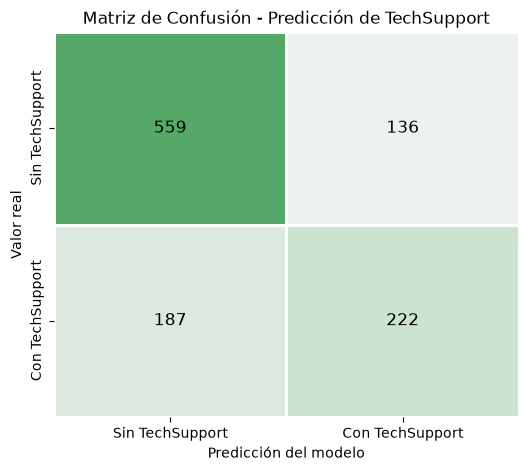

In [44]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz_support,
    annot=False,
    cmap=sns.light_palette("#55A868", as_cmap=True),
    cbar=False,
    linewidths=1,
    linecolor="white",
    xticklabels=["Sin TechSupport", "Con TechSupport"],
    yticklabels=["Sin TechSupport", "Con TechSupport"]
)

for fila in range(matriz_support.shape[0]):
    for columna in range(matriz_support.shape[1]):
        plt.text(
            columna + 0.5,
            fila + 0.5,
            matriz_support[fila, columna],
            ha="center",
            va="center",
            color="black",
            fontsize=12
        )

plt.title("Matriz de Confusión - Predicción de TechSupport")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.show()

### Interpretación de las métricas en este problema

- **Accuracy:** proporción total de clientes clasificados correctamente.
- **Precision:** de todos los clientes señalados como posibles candidatos a soporte, qué proporción realmente pertenece al grupo que ya tiene TechSupport.
- **Recall:** de todos los clientes que tienen TechSupport, qué proporción logró identificar el modelo.
- **F1-Score:** combina Precision y Recall en una sola medida.
- **Balanced Accuracy:** promedia el acierto en las dos clases, de manera que la mayoría sin soporte no domine el resultado.

Si contactar clientes fuera costoso o molesto, interesaría una Precision alta, para evitar ofrecimientos innecesarios. Si el contacto fuera barato y se buscara llegar a la mayor cantidad posible de candidatos, interesaría más el Recall. La métrica más importante depende de cuál de esos dos errores resulte más costoso para la empresa.

### Conclusión de la Parte II

La matriz de confusión muestra que el KNN clasifica correctamente a una parte importante de los clientes sin soporte e identifica a más de la mitad de quienes sí lo tienen, aunque también produce falsos positivos y deja clientes positivos sin detectar.

El KNN supera el Accuracy del modelo naive, por lo que aporta información adicional y no se limita a repetir la clase mayoritaria. Balanced Accuracy confirma que el desempeño es moderado al considerar por igual a los clientes con y sin soporte.

Precision es mayor que Recall: una parte considerable de los clientes señalados por el modelo pertenece realmente al grupo que tiene soporte, pero todavía quedan clientes positivos sin detectar. Para una campaña con contacto costoso, una Precision más alta ayuda a limitar ofrecimientos innecesarios. Si el contacto fuera barato y se buscara cubrir la mayor cantidad posible de perfiles, Recall sería la principal limitación.

Utilizamos variables demográficas, `tenure`, tipo de Internet, contrato, forma de pago y otros servicios contratados, y excluimos las variables que contenían directamente `TechSupport` o podían reflejar su precio. El modelo muestra que estas características permiten reconocer parcialmente un perfil asociado con la contratación de soporte, aunque no permiten afirmar que un cliente en particular vaya a contratarlo.

La principal limitación es que el dataset registra si el servicio está contratado, no la intención de compra, la respuesta a una campaña, reclamos, fallas técnicas ni el uso reciente del servicio. Por eso, en este contexto, "cliente potencial" significa un cliente cuyo perfil se asemeja al de quienes ya tienen TechSupport, no una garantía de que vaya a contratarlo.

# Conclusiones generales del TP

En la Parte I trabajamos con `Churn`. Convertimos `TotalCharges` a formato numérico y asignamos 0 a los clientes nuevos con `tenure = 0`. Los índices de Train, Validation y Test se reservaron antes de analizar las combinaciones de Churn utilizadas para crear nuevas variables. El encoder, el scaler y Feature Selection aprendieron solamente de Train; Validation se usó para comparar alternativas, y Test permaneció reservado hasta el final.

Comparamos cuatro representaciones, cada una con todas sus variables, Forward y Backward. La alternativa guardada automáticamente fue Opción 1 - Forward. Usamos Balanced Accuracy porque permite comparar de manera equilibrada el desempeño sobre Churn y No Churn, aunque no se trata de una métrica universalmente superior: Precision sería más importante para evitar contactos costosos, y Recall, para evitar dejar abandonos sin detectar.

El KNN final de Churn superó al modelo naive por un margen moderado. Con Oversampling aumentaron Recall y Balanced Accuracy, a cambio de más falsos positivos y menor Precision. Esta comparación muestra que la métrica a priorizar depende del objetivo y del costo de cada error.

En la Parte II cambiamos el target a `TechSupport`, excluyendo variables que contenían directamente el target o podían reflejar su precio. El KNN superó al modelo naive y mostró un desempeño moderado sobre ambas clases, lo que sugiere que este segundo problema presenta señales útiles con las variables elegidas.

Este segundo modelo identifica perfiles similares a los de quienes ya tienen soporte técnico, pero no mide intención de compra real. Para mejorar esto en una futura iteración, sería útil contar con datos sobre reclamos, fallas técnicas, uso del servicio o respuestas a campañas anteriores, información que actualmente no está disponible en el dataset. En ambos problemas, la interpretación de las métricas depende de la pregunta que se busca responder y de las decisiones que se tomarán a partir del modelo.